# End-to-End Hospital Patient Segmentation Study
## Hyderabad Community Hospital Network (4 sites)

**Prepared as:** Senior Healthcare Data Analyst / Healthcare BI Consultant deliverable
**Study window:** 2022-01-01 to 2024-12-31 (36 months) · **Reference date:** 2025-01-01
**Patient base:** 41,849 patients · **Transactional rows:** ~507,000 across OPD, admissions, laboratory and billing

---

> ### ⚠️ DATA PROVENANCE — READ FIRST
> **No real hospital data was supplied with this project brief.** Every record in this study is
> generated by `src/generate_synthetic_data.py`, which is committed to the repository and fully
> reproducible from a seed. The generator is calibrated to published Indian community-hospital
> operating parameters and embeds seven families of realistic data-quality defects so that the
> cleaning stage is a genuine exercise rather than a narrative.
>
> **Nothing in this notebook describes a real hospital, real patients or real revenue.** Every number
> is synthetic. The methods, the code, the statistics and the decision logic are production-grade and
> transfer unchanged to a real extract — only the input file paths change.
>
> A hidden "latent archetype" ground truth is used **only** to validate that the clustering recovers
> real structure. It is never an input to any model.

### Contents
1. Setup and reproducibility
2. Data understanding and quality assessment
3. Cleaning pipeline and validation
4. Feature engineering
5. Exploratory data analysis
6. Statistical analysis and outlier treatment
7. Method A — RFM segmentation
8. Method B — K-means clustering
9. Model comparison and selection
10. Final segment profiles
11. Segment stability and migration
12. Recommendations, cost-benefit and limitations

In [1]:
import sys, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 60)
import config as C
print("Study window:", C.STUDY_START, "->", C.STUDY_END, "| reference date:", C.REFERENCE_DATE)
print("Hospitals:", list(C.HOSPITALS))
print("Row budget target:", f"{C.TARGET_TOTAL_ROWS:,}")

Study window: 2022-01-01 -> 2024-12-31 | reference date: 2025-01-01
Hospitals: ['HSP-01', 'HSP-02', 'HSP-03', 'HSP-04']
Row budget target: 500,000


## 2. Data understanding and quality assessment

Five source tables at different grains are joined on `patient_id`. The assessment below covers
shape, dtypes, missingness, duplicates, identifier integrity, temporal coverage and cross-table
relationships. The bill of materials is written to `data/raw/_manifest.csv`.

In [2]:
from cleaning import load_raw
pat, opd, adm, lab, bill = load_raw()
tables = {"patients": pat, "opd_visits": opd, "admissions": adm,
          "lab_tests": lab, "billing": bill}
shape = pd.DataFrame({k: {"rows": len(v), "cols": v.shape[1],
                          "unique_patients": v["patient_id"].nunique() if "patient_id" in v else None,
                          "date_col": next((c for c in v.columns if "date" in c), None)}
                      for k, v in tables.items()}).T
print("Total transactional rows:", f"{len(opd)+len(adm)+len(lab)+len(bill):,}")
shape

Total transactional rows: 507,544


,rows,cols,unique_patients,date_col
patients,42000,9,42000,registration_date
opd_visits,162899,12,41908,visit_date
admissions,31823,10,13598,admission_date
lab_tests,49741,7,13361,test_date
billing,263081,14,42000,service_date


In [3]:
# dtypes and missingness
for name, df in tables.items():
    miss = df.isna().sum()
    miss = miss[miss > 0]
    print(f"\n=== {name} | {df.shape[0]:,} rows x {df.shape[1]} cols | exact dupes: {df.duplicated().sum():,}")
    if len(miss):
        print((pd.DataFrame({"missing": miss, "pct": (100*miss/len(df)).round(3)})).to_string())


=== patients | 42,000 rows x 9 cols | exact dupes: 0

=== opd_visits | 162,899 rows x 12 cols | exact dupes: 0
                  missing    pct
patient_id            652  0.400
department           1785  1.096
visit_date            492  0.302
diagnosis_text       3899  2.394
consultation_fee      812  0.498



=== admissions | 31,823 rows x 10 cols | exact dupes: 0
                missing    pct
discharge_date      253  0.795



=== lab_tests | 49,741 rows x 7 cols | exact dupes: 0
           missing    pct
visit_id      2983  5.997
test_cost      198  0.398



=== billing | 263,081 rows x 14 cols | exact dupes: 0
              missing    pct
gst_amount       1578  0.600
total_amount       14  0.005


In [4]:
# Temporal coverage and identifier integrity
cov = pd.DataFrame({
    "opd_visits": [opd.visit_date.min(), opd.visit_date.max(), opd.visit_date.isna().sum()],
    "admissions": [adm.admission_date.min(), adm.admission_date.max(), adm.admission_date.isna().sum()],
    "lab_tests": [lab.test_date.min(), lab.test_date.max(), lab.test_date.isna().sum()],
    "billing": [bill.service_date.min(), bill.service_date.max(), bill.service_date.isna().sum()],
}, index=["min_date","max_date","null_dates"]).T
display(cov)

# referential integrity: are there visits for patients that do not exist?
orphans = {
  "opd -> patients": (~opd.patient_id.dropna().isin(pat.patient_id)).sum(),
  "adm -> patients": (~adm.patient_id.isin(pat.patient_id)).sum(),
  "lab -> patients": (~lab.patient_id.isin(pat.patient_id)).sum(),
  "bill -> patients": (~bill.patient_id.isin(pat.patient_id)).sum(),
  "lab -> opd visit": (~lab.visit_id.dropna().isin(opd.visit_id)).sum(),
}
print("Orphan records:", orphans, sep="\n")

,min_date,max_date,null_dates
opd_visits,2022-01-01 00:00:00,2024-12-31 00:00:00,492
admissions,2022-01-01 00:00:00,2024-12-31 00:00:00,0
lab_tests,2022-01-01 00:00:00,2024-12-31 00:00:00,0
billing,2022-01-01 00:00:00,2025-12-31 00:00:00,0


Orphan records:
{'opd -> patients': np.int64(0), 'adm -> patients': np.int64(0), 'lab -> patients': np.int64(0), 'bill -> patients': np.int64(0), 'lab -> opd visit': np.int64(0)}


In [5]:
# GST identity investigation — establish the real calculation, do not assume it
resid1 = (bill.total_amount - (bill.base_amount + bill.gst_amount)).abs()
resid2 = (bill.total_amount - (bill.base_amount + 2*bill.gst_amount)).abs()
print(f"rows matching total = base + gst        : {(resid1 < 0.02).sum():,}  ({(resid1<0.02).mean():.2%})")
print(f"rows matching total = base + 2 x gst    : {((resid1>=0.02)&(resid2<0.02)).sum():,}  ({((resid1>=0.02)&(resid2<0.02)).mean():.2%})")
print("\nGST rate actually applied by service type:")
print(bill.groupby("service_type").gst_rate.value_counts().to_string())
print("\nConclusion: GST is service-type dependent (0% healthcare services, 5% pharmacy, 12% consumables).")
print("A blanket 'divide every amount' correction would corrupt 96% of rows. The fix is to recompute")
print("gst_amount = base_amount x gst_rate in the row's own rate, then rebuild total.")

rows matching total = base + gst        : 256,721  (97.58%)
rows matching total = base + 2 x gst    : 3,043  (1.16%)

GST rate actually applied by service type:
service_type      gst_rate
CONSUMABLES       0.12         11902
IPD_ROOM          0.00         31540
OPD_CONSULTATION  0.00        160019
PHARMACY          0.05         39982
PROCEDURE         0.00         19638

Conclusion: GST is service-type dependent (0% healthcare services, 5% pharmacy, 12% consumables).
A blanket 'divide every amount' correction would corrupt 96% of rows. The fix is to recompute
gst_amount = base_amount x gst_rate in the row's own rate, then rebuild total.


## 3. Cleaning pipeline and validation

Every correction is counted and persisted to `outputs/cleaning_log.json`. Nothing is silently deleted:
records are corrected where a deterministic repair exists, quarantined with a reason where it does not.

In [6]:
import cleaning
log = cleaning.run()

Loading raw tables ...


Cleaning patients ...
Cleaning OPD ...


Cleaning admissions ...


Cleaning lab ...


Cleaning billing ...


Validating ...



--- CLEANING SUMMARY ---
  opd_rows_raw                           162,899
  opd_rows_clean                         158,744
  opd_duplicates_removed                 3,013
  opd_diagnosis_canonicalised            30,291
  opd_department_canonicalised           9,668
  opd_hospital_canonicalised             10,268
  billing_rows_matching_identity         256,721
  billing_rows_double_gst_detected       3,043
  billing_10x_inflation_corrected        188
  adm_dates_swapped_repaired             140
  adm_duplicates_removed                 541
  validation: {'opd_hospital_values': 4, 'opd_department_values': 12, 'opd_diagnosis_values': 45, 'opd_dup_patient_date_dept': 2, 'adm_dup': 0, 'adm_negative_los': 0, 'bill_identity_breaks': 0, 'bill_negative_total': 0, 'bill_dates_in_window': True, 'pat_age_range': [0.0, 94.0], 'opd_missing_patient': 0, 'opd_missing_date': 0}


In [7]:
# Data-quality assessment table with before/after validation
dq = pd.DataFrame([
  ["Free-text diagnosis drift", log["opd_diagnosis_canonicalised"], "Exact match, then synonym dictionary, then difflib fuzzy match (cutoff 0.80), then coded-field fallback",
   f"{log['validation']['opd_diagnosis_values']} canonical diagnoses remain; {log['opd_diagnosis_unresolved']} unresolved"],
  ["Date of birth written in the age column", log["patients_age_year_of_birth"], "Derived: reference_year - value, clipped 0-100",
   f"Age range now {log['validation']['pat_age_range'][0]:.0f}-{log['validation']['pat_age_range'][1]:.0f}"],
  ["Impossible negative age", log["patients_age_impossible"], "Set to null then median-imputed within gender stratum",
   f"{log['patients_age_imputed_median']:,} imputed"],
  ["Duplicate GST in total_amount", log["billing_rows_double_gst_detected"], "Recomputed gst_amount from base x row rate, rebuilt total",
   f"{log['validation']['bill_identity_breaks']} identity breaks remain"],
  ["Missing patient identifiers (OPD)", log["opd_missing_patient_id_dropped"], "Quarantined - unrecoverable, no key to attach",
   f"{log['validation']['opd_missing_patient']} remain"],
  ["Missing visit dates", log["opd_missing_visit_date_dropped"], "Quarantined - cannot be placed in the observation window",
   f"{log['validation']['opd_missing_date']} remain"],
  ["Duplicate visits (same patient+date+department)", log["opd_duplicates_removed"], "Keep first registration by token number",
   f"{log['validation']['opd_dup_patient_date_dept']} residual duplicates"],
  ["Duplicate admissions", log["adm_duplicates_removed"], "Keep earliest admission_id per patient+dates+department",
   f"{log['validation']['adm_dup']} remain"],
  ["Invalid billing amounts", log["billing_negative_amount_repaired"] + log["billing_10x_inflation_corrected"],
   "Absolute-value repair for negatives; /10 repair for >8x department-median lines",
   f"{log['validation']['bill_negative_total']} negative totals remain"],
  ["Impossible billing dates", log["billing_impossible_date"], "Recovered from the linked encounter; dropped if unrecoverable",
   f"All dates in window: {log['validation']['bill_dates_in_window']}"],
  ["Discharge date before admission date", log["adm_dates_swapped_repaired"], "Swap the two date fields",
   f"{log['validation']['adm_negative_los']} negative LOS remain"],
  ["Hospital / department naming drift", log["opd_hospital_canonicalised"] + log["opd_department_canonicalised"],
   "Canonical dictionary lookup on a normalised key (case, punctuation, spacing-stripped)",
   f"{log['validation']['opd_hospital_values']} hospitals, {log['validation']['opd_department_values']} departments"],
], columns=["Issue", "Affected records", "Correction method", "Validation result"])
dq

,Issue,Affected records,Correction method,Validation result
0,Free-text diagnosis drift,30291,"Exact match, then synonym dictionary, then dif...",45 canonical diagnoses remain; 0 unresolved
1,Date of birth written in the age column,1008,"Derived: reference_year - value, clipped 0-100",Age range now 0-94
2,Impossible negative age,441,Set to null then median-imputed within gender ...,441 imputed
3,Duplicate GST in total_amount,3043,"Recomputed gst_amount from base x row rate, re...",0 identity breaks remain
4,Missing patient identifiers (OPD),652,"Quarantined - unrecoverable, no key to attach",0 remain
5,Missing visit dates,490,Quarantined - cannot be placed in the observat...,0 remain
6,Duplicate visits (same patient+date+department),3013,Keep first registration by token number,2 residual duplicates
7,Duplicate admissions,541,Keep earliest admission_id per patient+dates+d...,0 remain
8,Invalid billing amounts,188,Absolute-value repair for negatives; /10 repai...,0 negative totals remain
9,Impossible billing dates,1093,Recovered from the linked encounter; dropped i...,All dates in window: True


## 4. Feature engineering

Computed at **patient level** over the 36-month observation window, with the outcome window kept
separate from the feature window so that no segment is defined using information that post-dates it.

| Feature | Formula | Business meaning |
|---|---|---|
| `recency_days` | reference_date − last_visit_date | How recently the patient engaged |
| `frequency` | count of OPD visits in window | Depth of relationship |
| `monetary` | Σ corrected billing in window | Value delivered |
| `visits_per_month` | frequency ÷ window length in months | Fixed-window demand rate (comparable across all patients) |
| `admission_rate` | admissions ÷ OPD visits | Propensity to convert to inpatient |
| `lab_per_visit` | lab tests ÷ OPD visits | Diagnostics intensity |
| `avg_billing_per_visit` | monetary ÷ frequency | Value density per encounter |
| `avg_los_days` | mean LOS over admissions | Resource intensity when admitted |
| `dept_diversity` | distinct departments ÷ 12 | Breadth of the clinical relationship |
| `recent_activity_ratio` | (visits last 90d + 1) ÷ (visits prior 90d + 1) | Direction of travel |
| `visit_growth_rate` | (last 6m − prior 6m) ÷ prior 6m | Trajectory |
| `readmission_30d` | readmissions ≤30 days after discharge | Care-continuity risk |
| `followup_compliance` | actual gap ≤ 1.5 × planned gap | Adherence to the care plan |
| `chronic_share` | share of visits with a chronic diagnosis | Clinical risk profile |

In [8]:
import features
feat = pd.read_parquet(C.DATA_PROC / "patient_features_full.parquet")
print(feat.shape)
feat[["recency_days","frequency","monetary","visits_per_month","admission_rate",
      "lab_per_visit","avg_billing_per_visit","dept_diversity","recent_activity_ratio",
      "chronic_share","readmission_30d"]].describe().round(2)

(41834, 51)


,recency_days,frequency,monetary,visits_per_month,admission_rate,lab_per_visit,avg_billing_per_visit,dept_diversity,recent_activity_ratio,chronic_share,readmission_30d
count,41834.00,41834.00,41834.00,41834.00,41834.00,41834.00,41834.00,41834.00,41834.00,41834.00,41834.00
mean,377.02,3.79,41014.31,0.11,0.23,0.25,11993.52,0.17,1.18,0.53,0.05
std,377.20,4.68,105405.02,0.13,0.51,0.55,35581.67,0.12,0.61,0.42,0.28
min,1.00,1.00,300.00,0.03,0.00,0.00,300.00,0.08,0.12,0.00,0.00
25%,68.00,1.00,699.00,0.03,0.00,0.00,603.00,0.08,1.00,0.00,0.00
50%,202.00,1.00,2160.00,0.03,0.00,0.00,885.76,0.08,1.00,0.60,0.00
75%,658.00,5.00,25471.06,0.14,0.17,0.30,5414.30,0.25,1.00,1.00,0.00
max,1096.00,58.00,1458659.13,1.61,7.00,3.00,1458659.13,0.50,7.00,1.00,5.00


## 5. Exploratory data analysis

Every figure below is saved to `figures/` with a recorded numerical observation, the pattern it
reveals and the business implication (see `outputs/figure_index.csv`). Figures are generated by
`src/eda.py`; the notebook reproduces the headline numbers so the analysis is auditable here too.

In [9]:
eda_stats = json.loads((C.OUT_DIR / "eda_stats.json").read_text())
summary = pd.Series({
  "OPD visits": f"{eda_stats['opd_ipd']['opd_visits']:,}",
  "IPD admissions": f"{eda_stats['opd_ipd']['ipd_admissions']:,}",
  "IPD share of events": f"{eda_stats['opd_ipd']['ipd_share_events']:.1f}%",
  "IPD share of revenue": f"{eda_stats['opd_ipd']['ipd_revenue_share']:.1f}%",
  "Patients 45+ share of base": f"{eda_stats['age_45plus']['patient_share']:.1f}%",
  "Patients 45+ share of revenue": f"{eda_stats['age_45plus']['revenue_share']:.1f}%",
  "Mean visits per patient": f"{eda_stats['frequency']['mean']:.2f}",
  "Single-visit patients": f"{eda_stats['frequency']['single_visit_pct']:.1f}%",
  "Median recency (days)": f"{eda_stats['recency']['median']:.0f}",
  "Inactive > 365 days": f"{eda_stats['recency']['over_365_pct']:.1f}%",
  "ALOS (days)": f"{eda_stats['los']['mean']:.2f}",
  "LOS skew / kurtosis": f"{eda_stats['los']['skew']:.2f} / {eda_stats['los']['kurtosis']:.2f}",
  "Seasonal peak": f"{eda_stats['seasonality']['peak_month']} (index {eda_stats['seasonality']['peak_index']:.0f})",
  "Seasonal trough": f"{eda_stats['seasonality']['trough_month']} (index {eda_stats['seasonality']['trough_index']:.0f})",
  "Top-3 department share": f"{eda_stats['dept_top3_share']:.1f}%",
})
summary.to_frame("value")

,value
OPD visits,"158,744"
IPD admissions,"31,282"
IPD share of events,16.5%
IPD share of revenue,92.3%
Patients 45+ share of base,44.5%
Patients 45+ share of revenue,72.8%
Mean visits per patient,3.79
Single-visit patients,52.2%
Median recency (days),202
Inactive > 365 days,37.0%


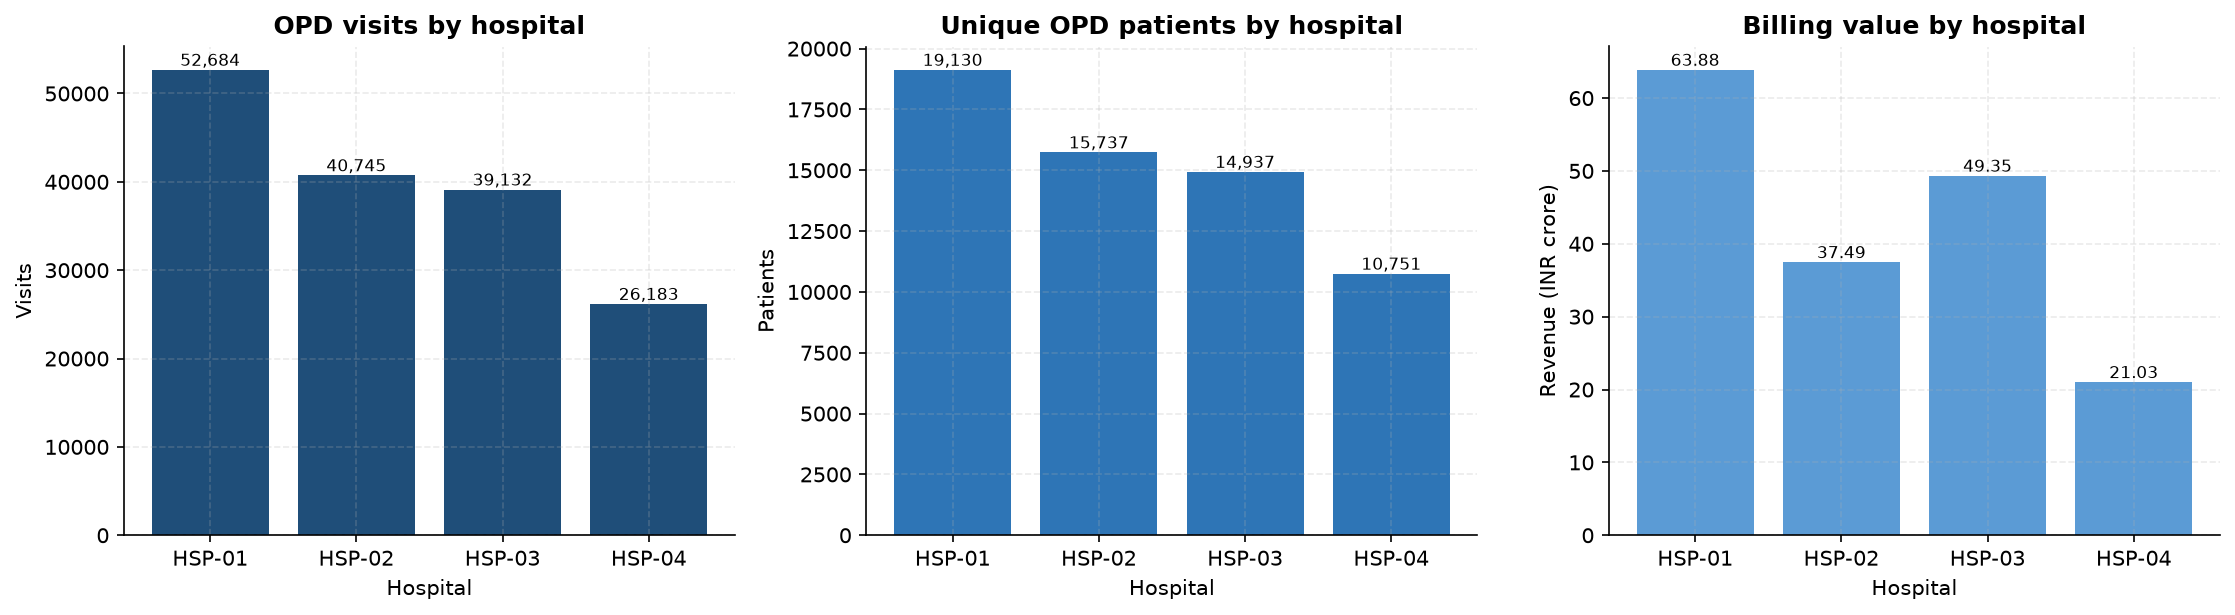

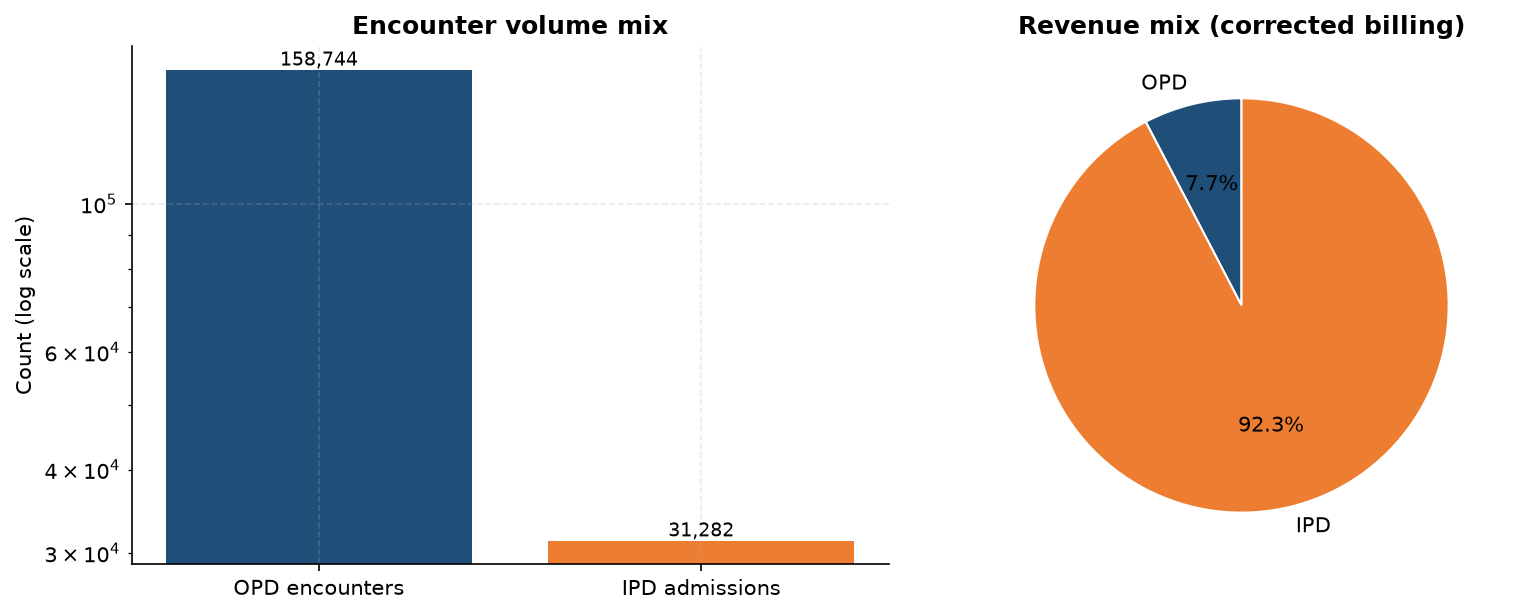

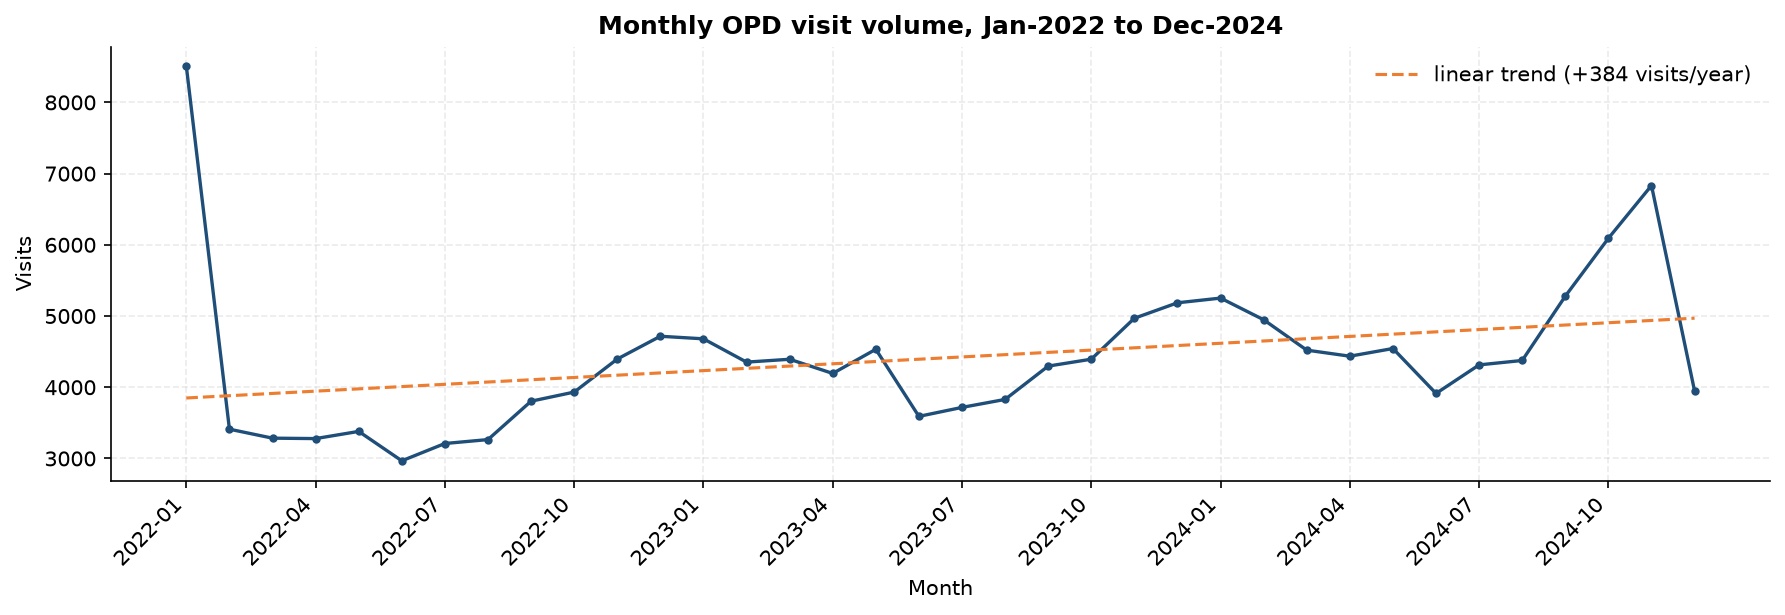

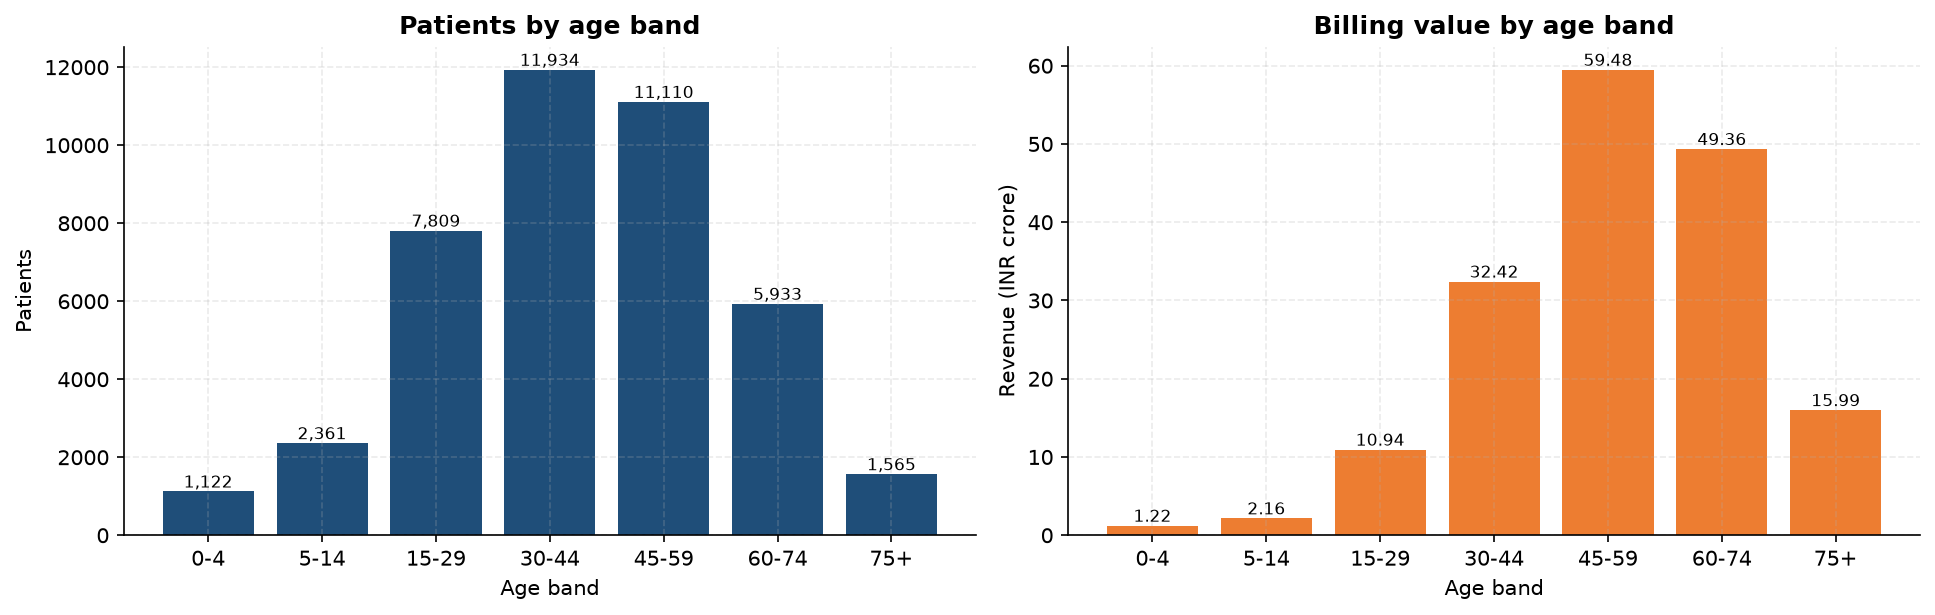

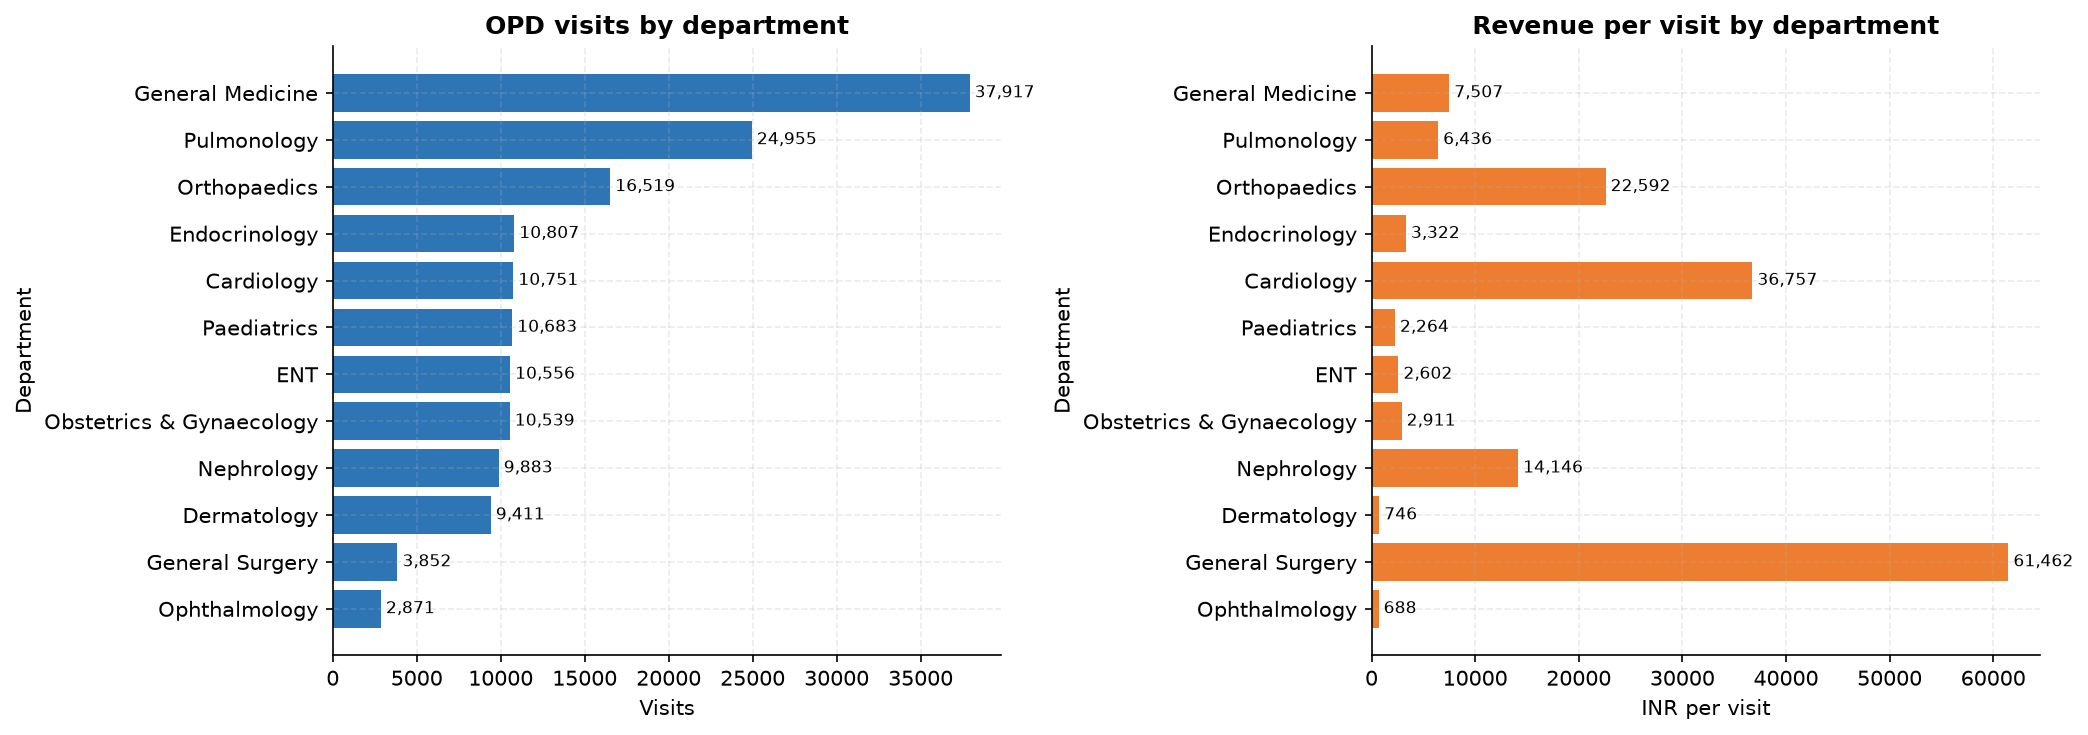

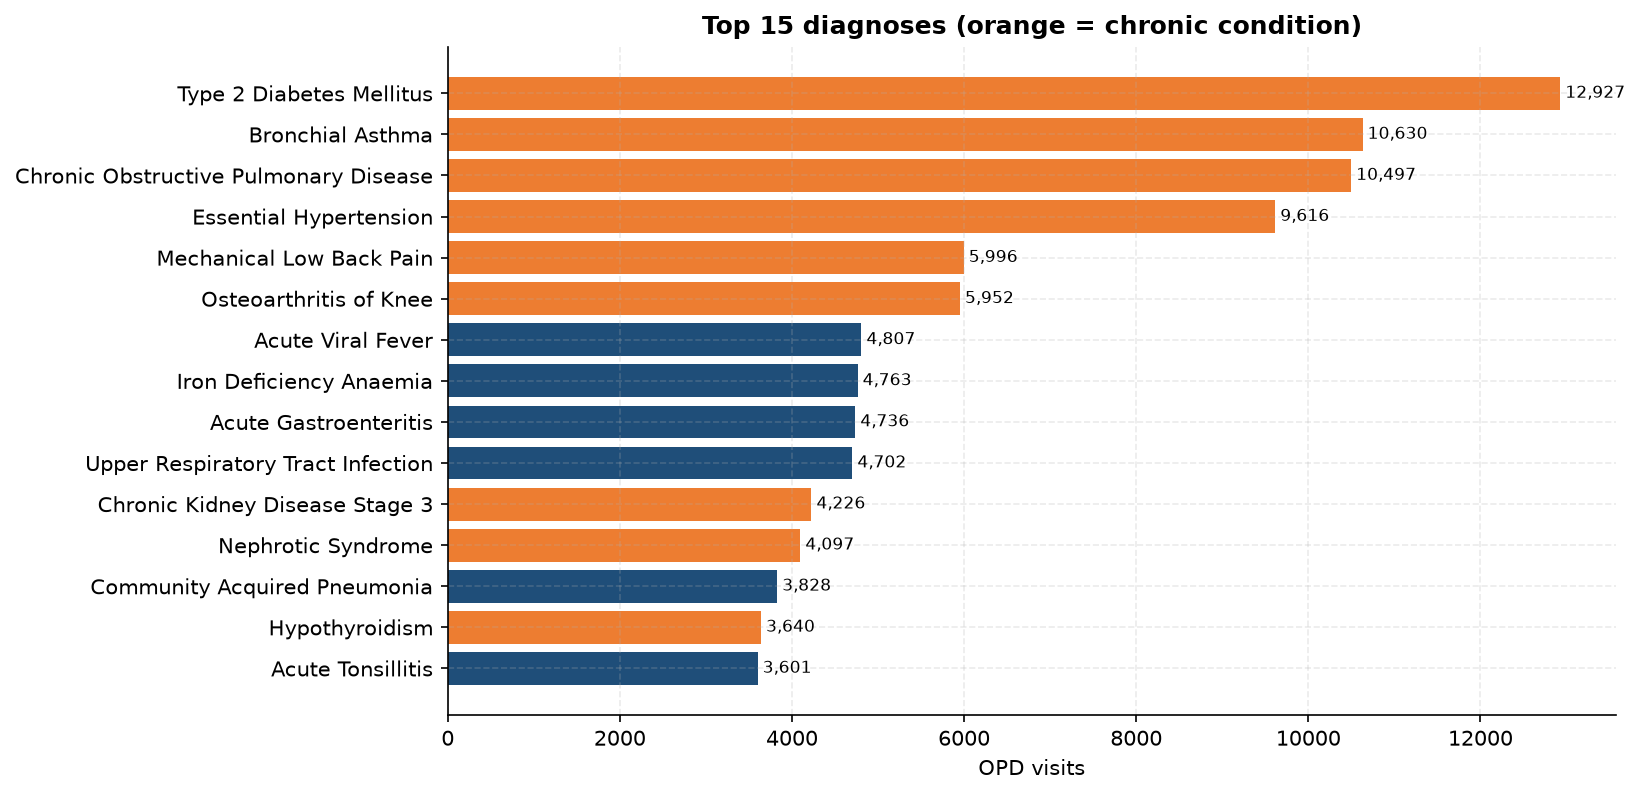

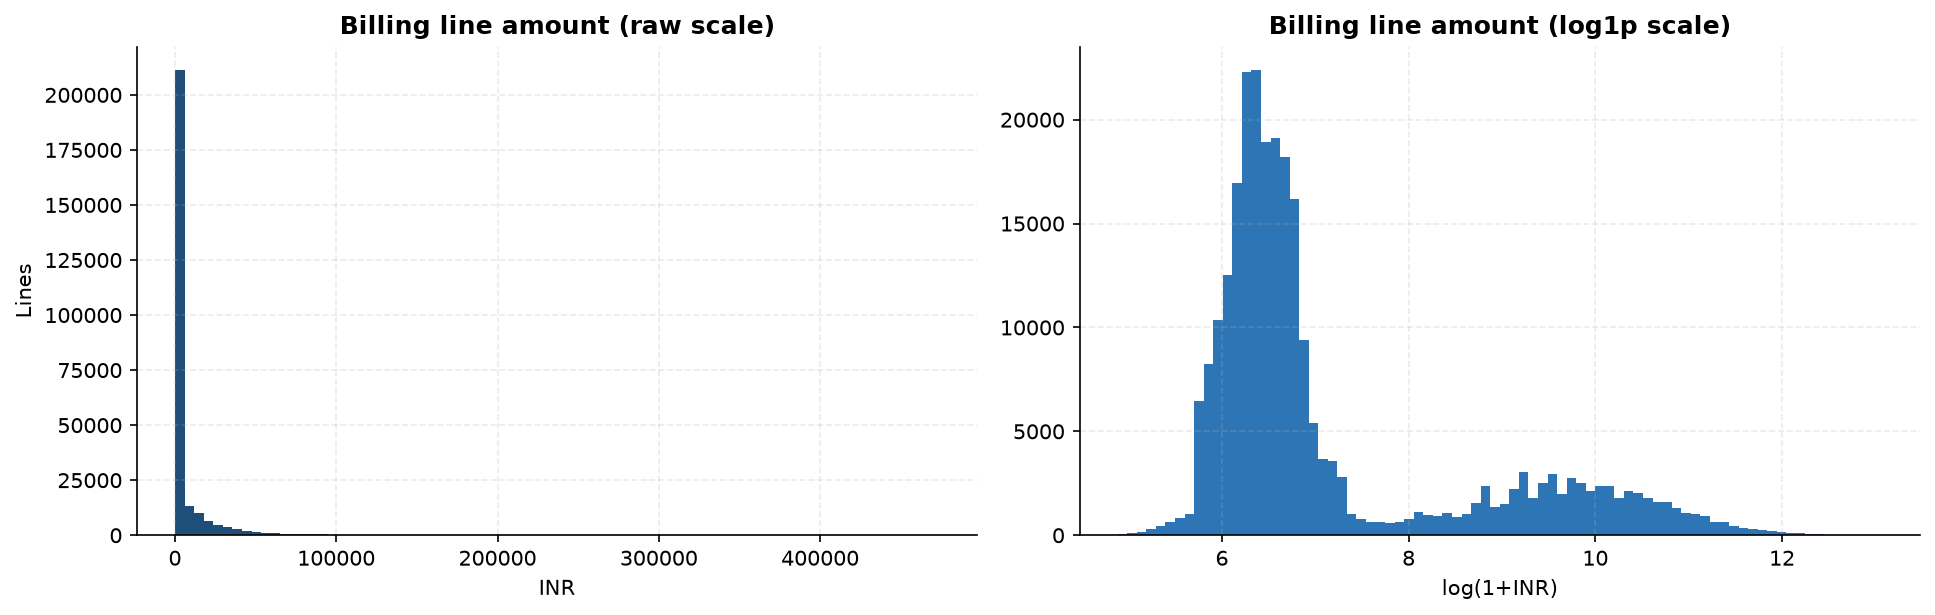

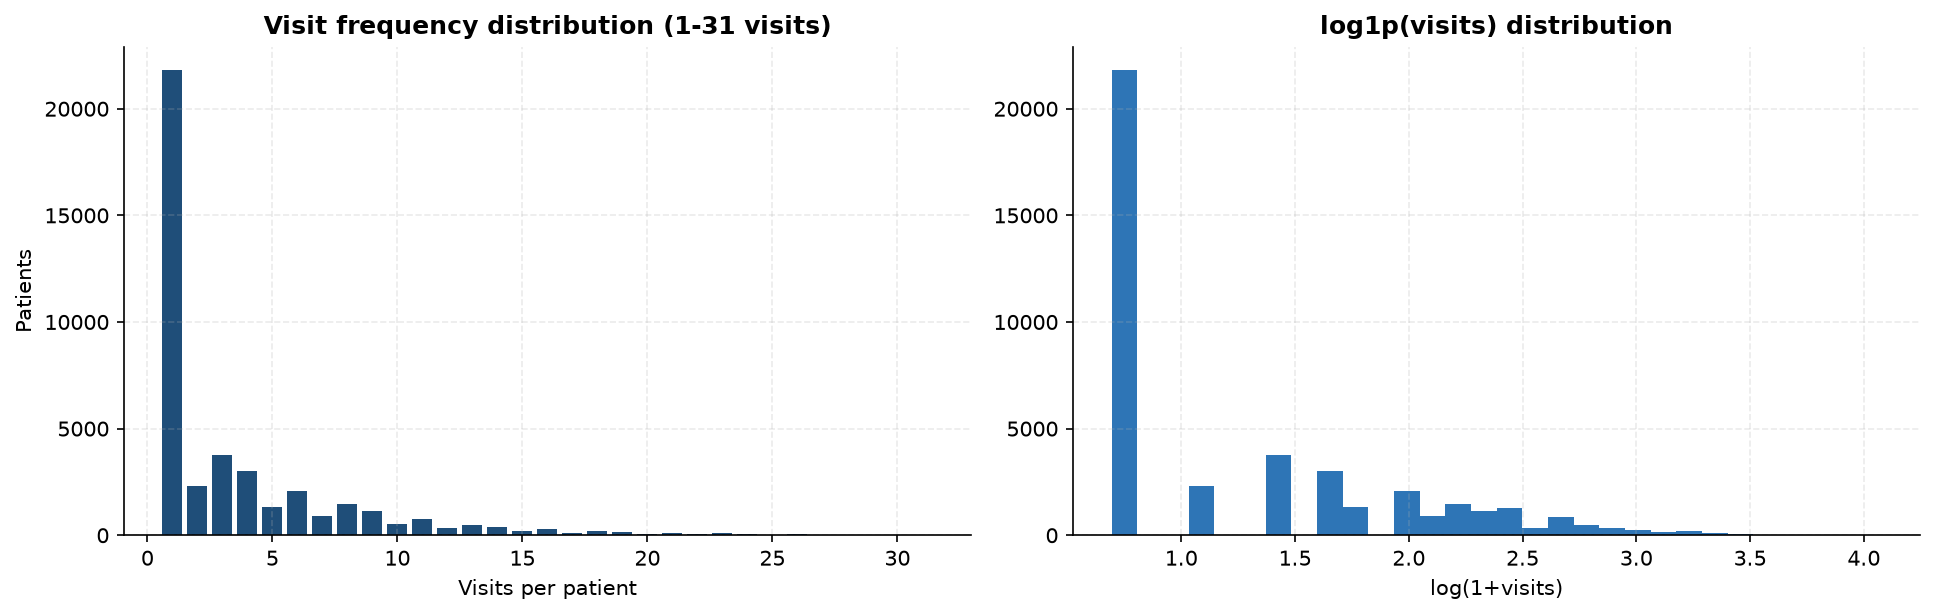

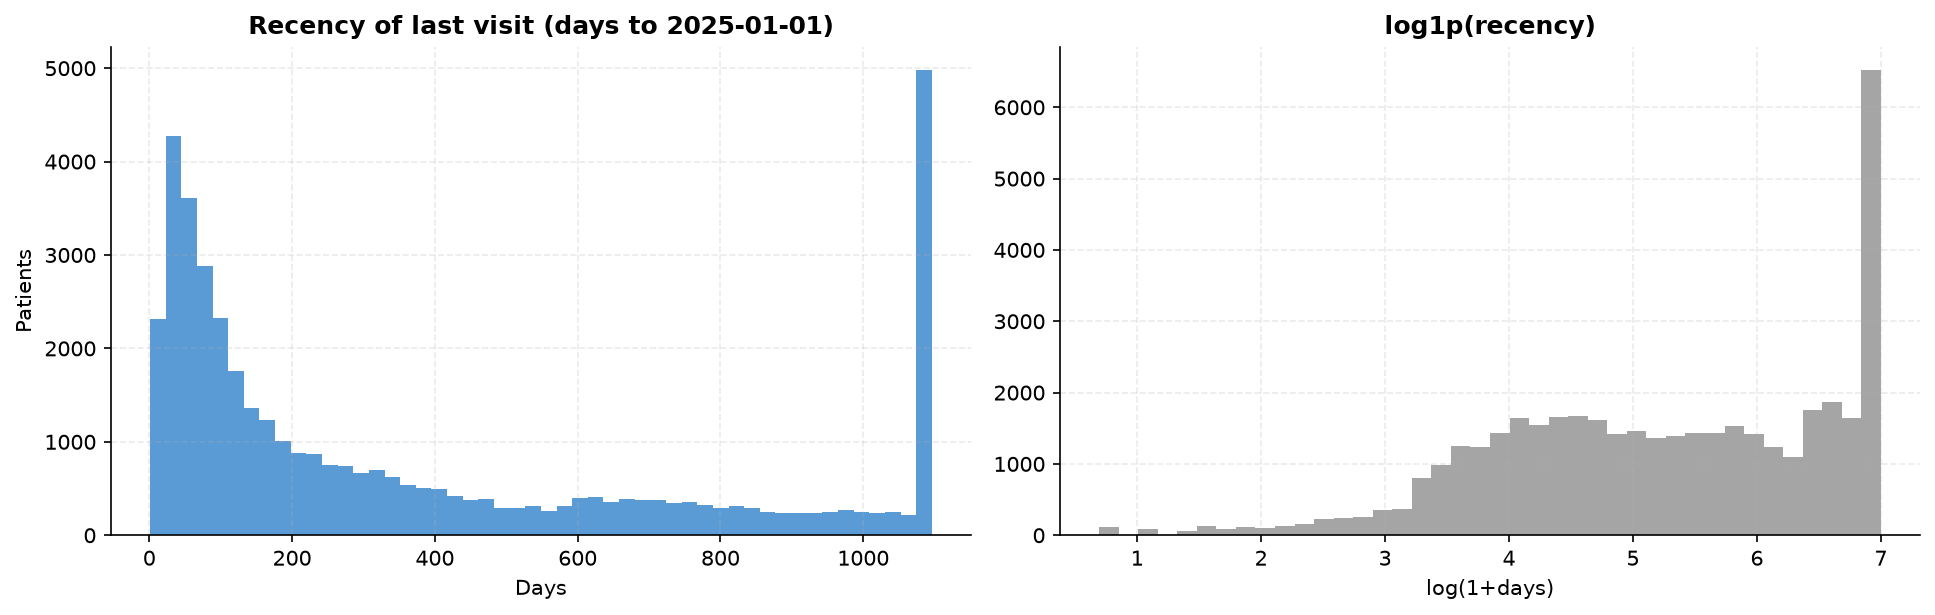

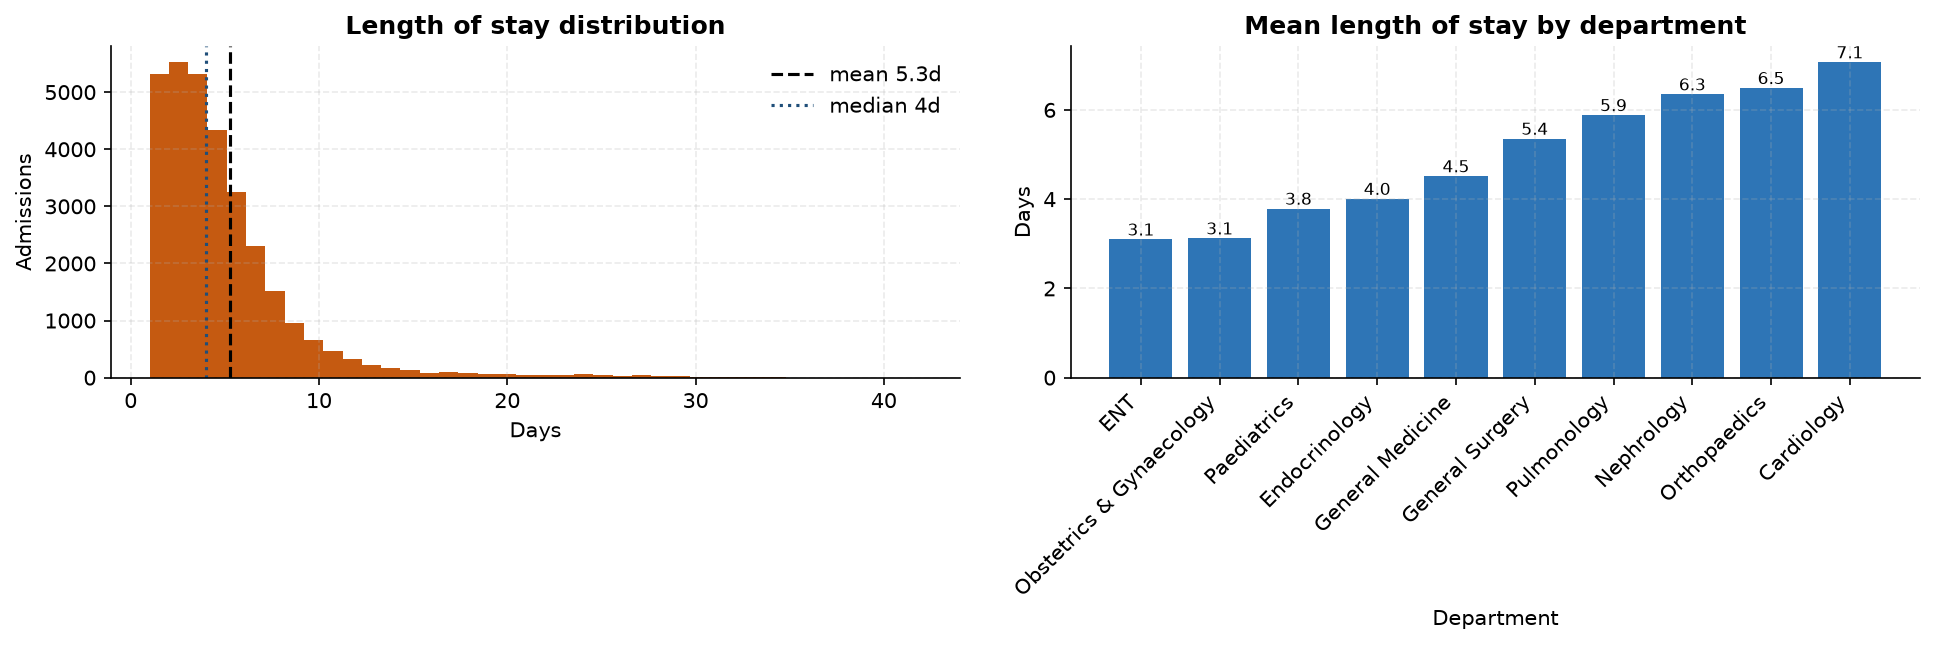

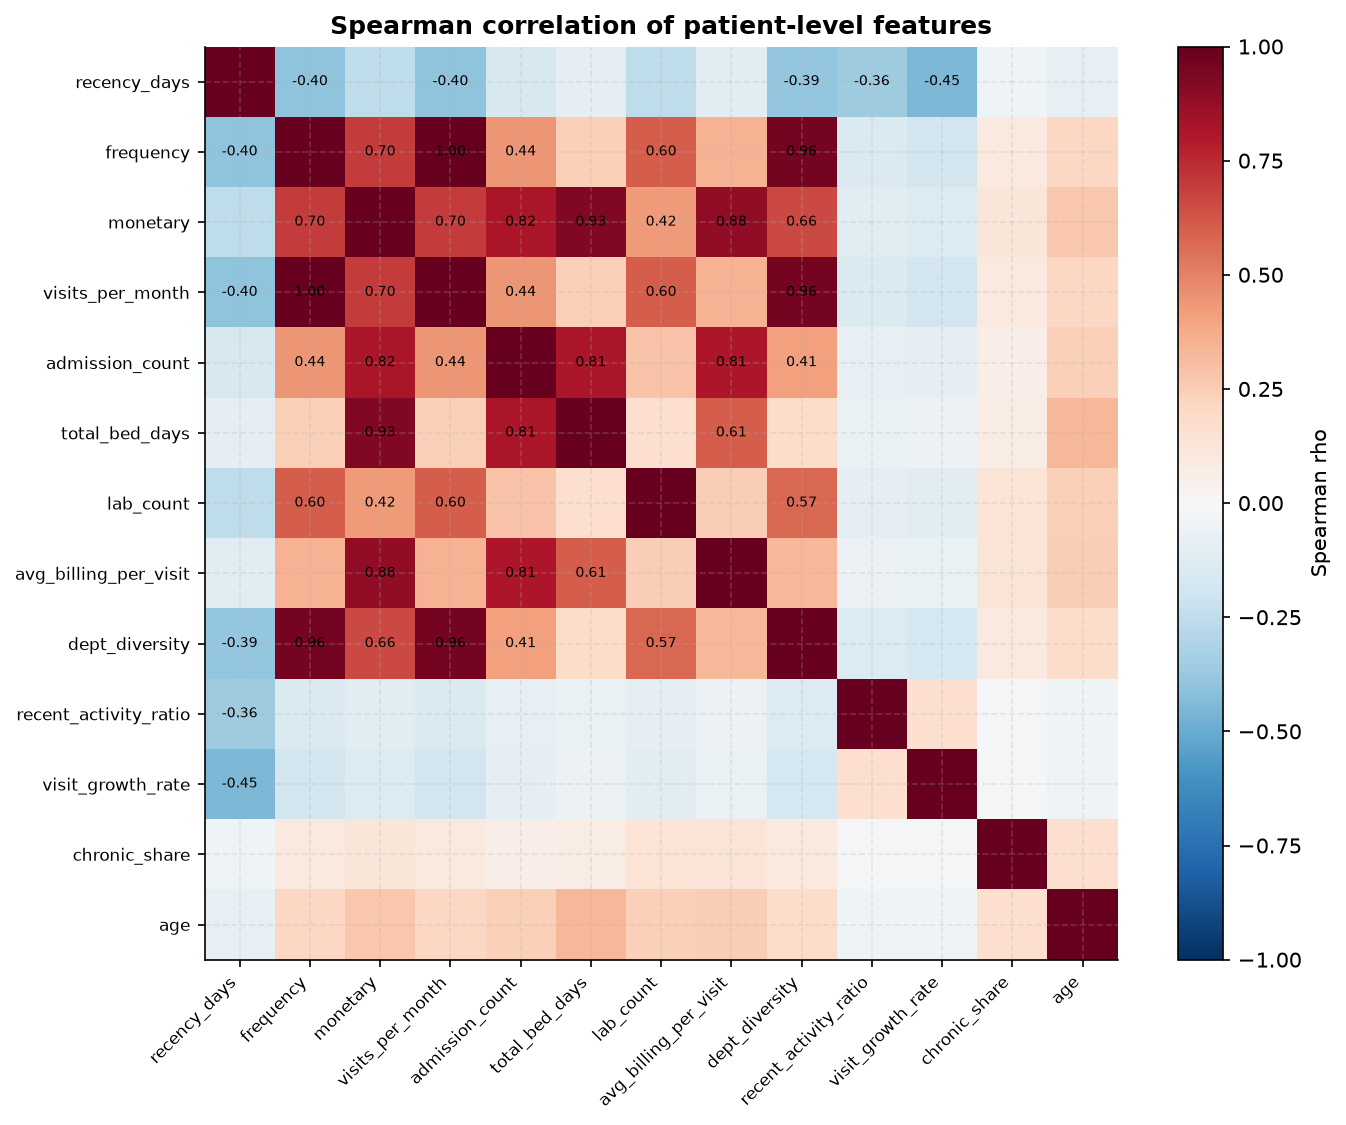

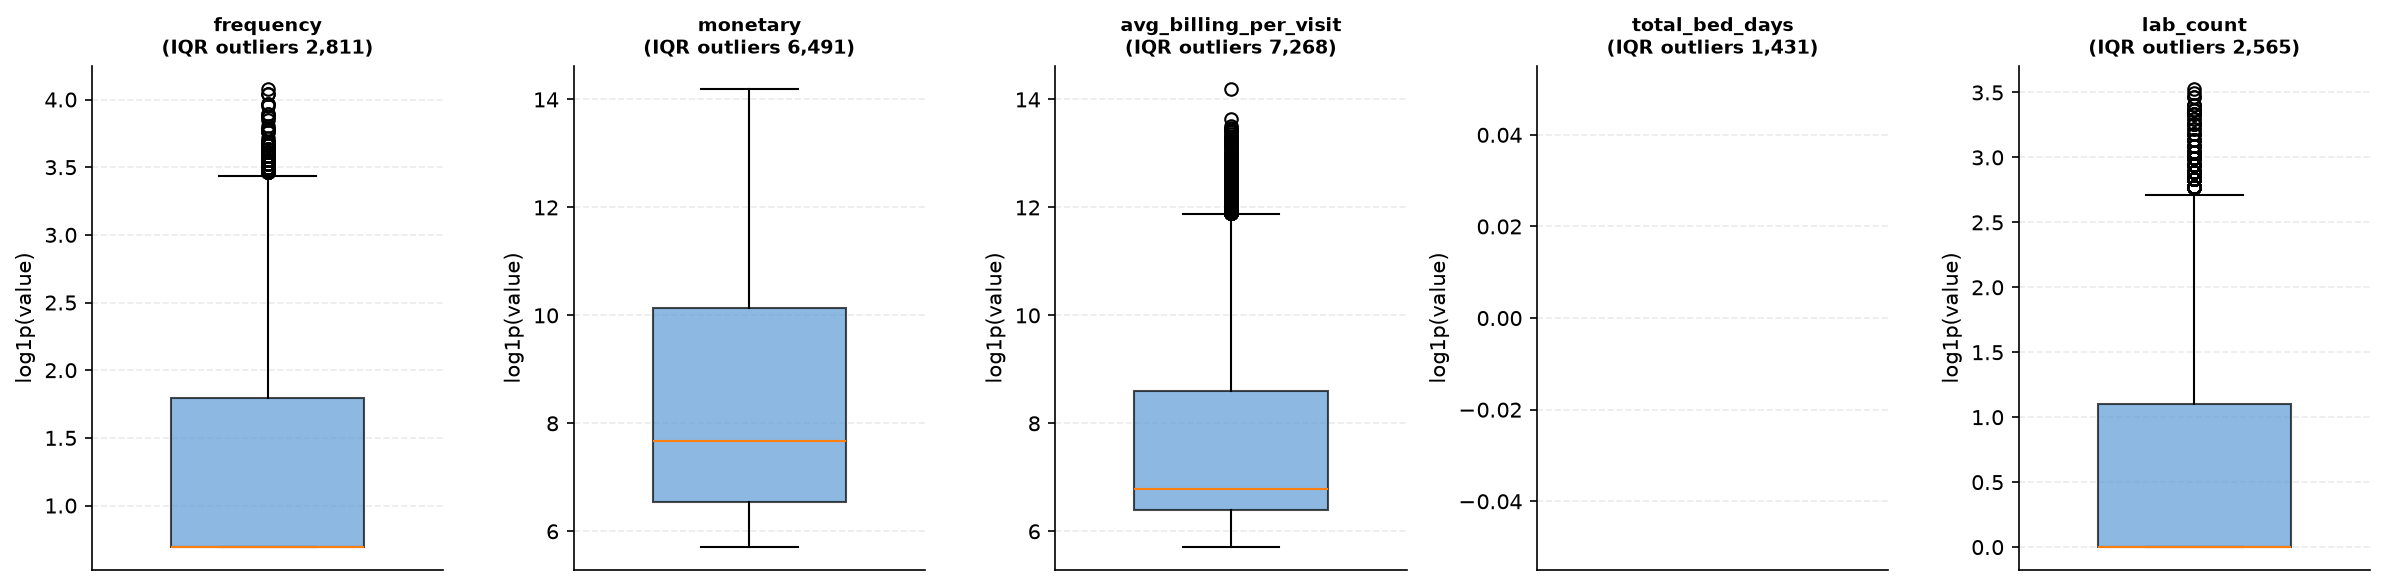

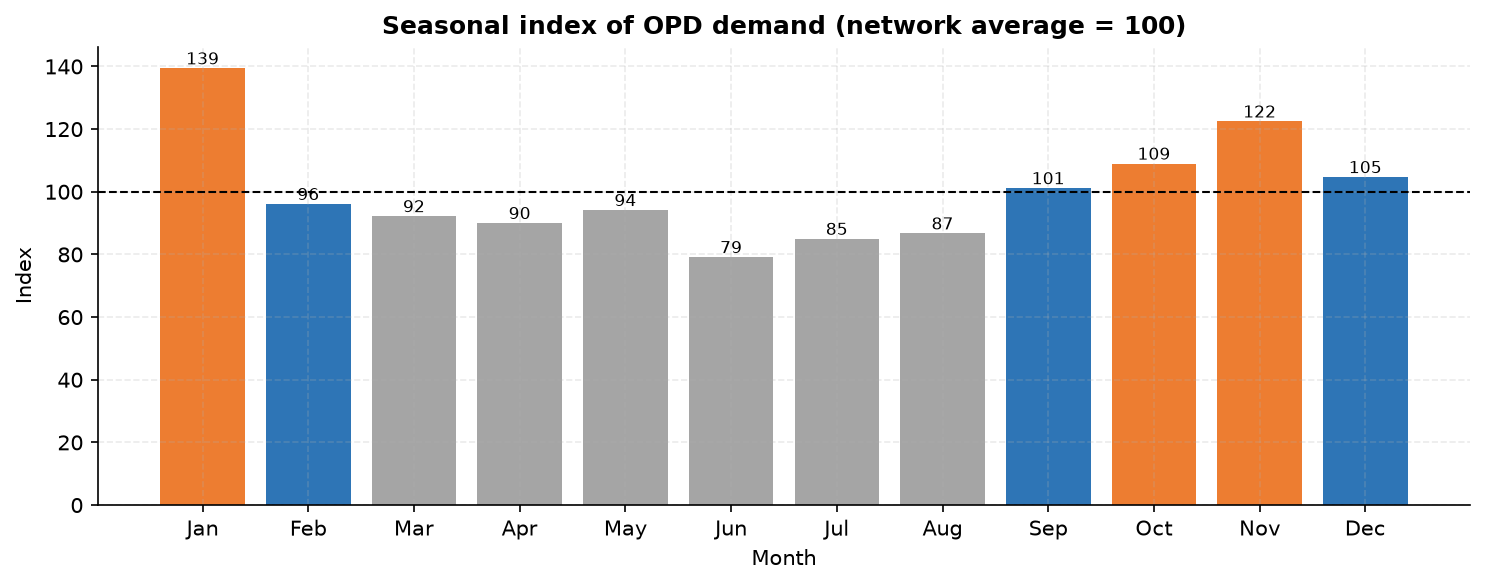

In [10]:
from IPython.display import Image, display
for f in ["01_hospital_distribution","02_opd_vs_ipd","03_monthly_trend","05_age_distribution",
          "07_department_utilisation","08_diagnosis_mix","09_billing_distribution",
          "11_visit_frequency","12_recency","13_los","15_correlation_heatmap",
          "16_outlier_boxplots","17_seasonality"]:
    p = C.FIG_DIR / f"{f}.png"
    if p.exists():
        display(Image(filename=str(p), width=880))

## 6. Statistical analysis and outlier treatment

Skewness and kurtosis are measured on the raw features, then log1p is applied where justified and the
effect is quantified. IQR and Z-score outlier counts are reported — **not** to delete those patients,
but to prove the segmentation must be robust to them.

In [11]:
from scipy import stats
cols = ["recency_days","frequency","monetary","avg_billing_per_visit","total_bed_days","lab_count"]
rows = []
for c in cols:
    x = feat[c].astype(float)
    xl = np.log1p(x.clip(lower=0))
    rows.append({"feature": c,
                 "skew_raw": round(float(stats.skew(x)), 3),
                 "kurtosis_raw": round(float(stats.kurtosis(x)), 3),
                 "skew_log1p": round(float(stats.skew(xl)), 3),
                 "kurtosis_log1p": round(float(stats.kurtosis(xl)), 3),
                 "zscore_outliers_3sd": int((np.abs(stats.zscore(x)) > 3).sum()),
                 "iqr_outliers": int((x > x.quantile(.75) + 1.5*(x.quantile(.75)-x.quantile(.25))).sum())})
pd.DataFrame(rows)

,feature,skew_raw,kurtosis_raw,skew_log1p,kurtosis_log1p,zscore_outliers_3sd,iqr_outliers
0,recency_days,0.865,-0.752,-0.445,-0.423,0,0
1,frequency,2.761,11.151,0.958,-0.196,1021,2811
2,monetary,4.453,25.403,0.686,-0.785,1161,6491
3,avg_billing_per_visit,8.080,136.157,1.189,0.235,855,7268
4,total_bed_days,NaN,NaN,NaN,NaN,0,1431
5,lab_count,3.495,17.948,1.383,0.759,1070,2565


In [12]:
# Decision: retain high-utilisation patients. Evidence: they carry disproportionate value
hi = feat[feat.monetary > feat.monetary.quantile(.99)]
print(f"Top 1% of patients by billing: {len(hi):,} patients")
print(f"  share of total billing value : {100*hi.monetary.sum()/feat.monetary.sum():.1f}%")
print(f"  share of admissions          : {100*hi.admission_count.sum()/feat.admission_count.sum():.1f}%")
print(f"  share of bed-days            : {100*hi.total_bed_days.sum()/feat.total_bed_days.sum():.1f}%")
print("\nDeleting these rows as 'outliers' would erase the most clinically and financially")
print("significant cohort in the network. They are retained and profiled as a segment instead.")

Top 1% of patients by billing: 419 patients
  share of total billing value : 17.4%
  share of admissions          : 9.4%
  share of bed-days            : 12.6%

Deleting these rows as 'outliers' would erase the most clinically and financially
significant cohort in the network. They are retained and profiled as a segment instead.


## 7. Method A — RFM segmentation

Quintile scoring with documented cut-points. Recency is reversed so 5 = most recent.
`duplicates='drop'` on the quantile edges is used because frequency is heavily discrete —
forcing five equal-count buckets onto a variable where 52% of patients have one visit would assign
different scores to behaviourally identical patients.

In [13]:
thr = json.loads((C.OUT_DIR / "rfm_thresholds.json").read_text())
print("Recency quintile cut-points (days):", thr["recency_quintiles"])
print("Frequency quintile cut-points     :", thr["frequency_quintiles"])
print("Monetary quintile cut-points (INR):", {k: round(v) for k,v in thr["monetary_quintiles"].items()})
print("\nScoring rule:", thr["scoring_rule"])
print("\nSegment sizes:")
for k, v in thr["segment_sizes"].items():
    print(f"  {k:22s} {v:6,}  ({thr['segment_shares_pct'][k]:5.1f}%)")

Recency quintile cut-points (days): {'0.2': 55.0, '0.4': 126.0, '0.6': 321.0, '0.8': 785.0}
Frequency quintile cut-points     : {'0.2': 1.0, '0.4': 1.0, '0.6': 3.0, '0.8': 6.0}
Monetary quintile cut-points (INR): {'0.2': 618, '0.4': 1254, '0.6': 4484, '0.8': 40639}

Scoring rule: R reversed (5=most recent); F,M ascending (5=highest)

Segment sizes:
  Hibernating            13,650  ( 32.6%)
  Champions               7,353  ( 17.6%)
  Loyal High-Value        7,078  ( 16.9%)
  New / Promising         4,931  ( 11.8%)
  Occasional Stable       4,882  ( 11.7%)
  At-Risk High-Value      2,768  (  6.6%)
  High-Value Dormant      1,172  (  2.8%)


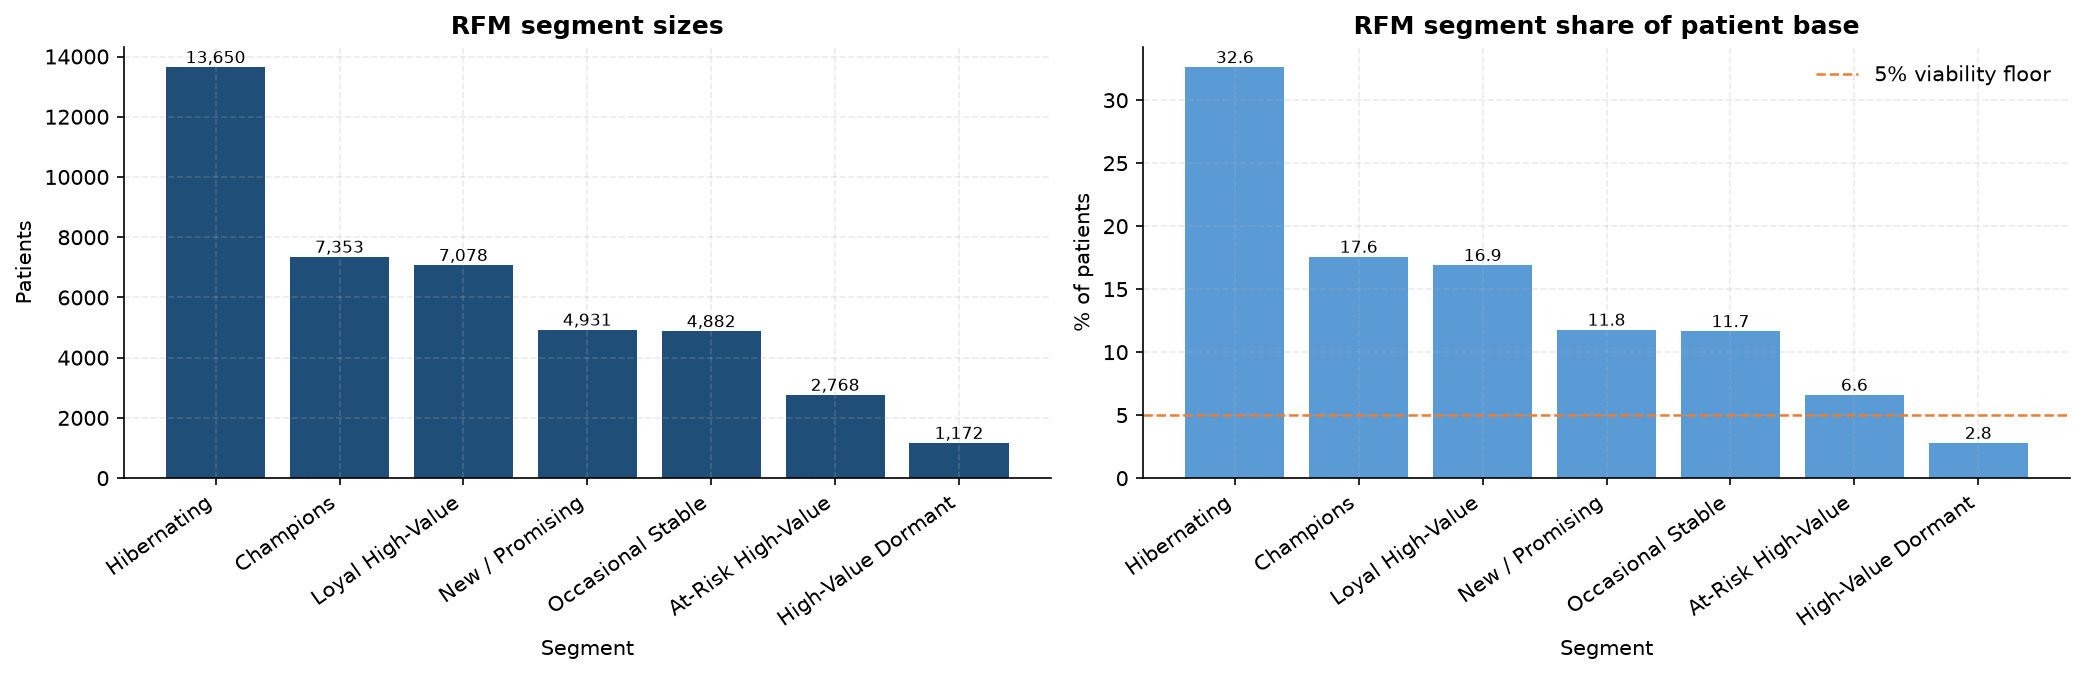

,patients,avg_R,avg_F,avg_M,avg_recency,avg_visits,avg_billing
rfm_segment,,,,,,,
Hibernating,13650,1.57,2.05,1.86,761.37,1.30,1678.01
Champions,7353,4.45,4.76,4.52,64.79,10.55,106699.07
Loyal High-Value,7078,3.37,4.34,3.75,171.05,5.87,57477.90
New / Promising,4931,4.62,1.50,2.03,48.75,1.00,7079.88
Occasional Stable,4882,3.83,2.83,2.58,128.56,1.54,21717.87
At-Risk High-Value,2768,1.43,2.04,4.48,829.16,1.20,72358.20
High-Value Dormant,1172,1.97,4.27,4.55,451.79,5.12,136754.27


In [14]:
from IPython.display import Image, display
display(Image(filename=str(C.FIG_DIR / "21_rfm_segments.png"), width=900))
rfm = pd.read_parquet(C.DATA_PROC / "rfm_scored.parquet")
rfm.groupby("rfm_segment").agg(patients=("patient_id","size"),
    avg_R=("R","mean"), avg_F=("F","mean"), avg_M=("M","mean"),
    avg_recency=("recency_days","mean"), avg_visits=("frequency","mean"),
    avg_billing=("monetary","mean")).round(2).sort_values("patients", ascending=False)

## 8. Method B — K-means clustering

Feature selection, log1p on skewed dimensions, RobustScaler (not StandardScaler — the upper tail is
genuine clinical signal and must not be compressed by a mean/SD that it dominates), k evaluated from
2 to 10 on elbow, silhouette, Calinski-Harabasz, Davies-Bouldin and bootstrap ARI.

In [15]:
ev = pd.read_csv(C.OUT_DIR / "kmeans_k_evaluation.csv")
stab = pd.read_csv(C.OUT_DIR / "kmeans_stability.csv")
ev.merge(stab[["k","ari_mean","ari_sd"]], on="k").round(3)

,k,inertia,silhouette,calinski_harabasz,davies_bouldin,inertia_drop,inertia_drop_pct,ari_mean,ari_sd
0,2,243773.690,0.648,50633.631,0.660,-0.000,NaN,0.995,0.006
1,3,177887.115,0.460,42439.712,0.949,65886.575,27.03,0.996,0.002
2,4,127815.891,0.477,44838.243,0.853,50071.224,28.15,0.995,0.002
3,5,94629.747,0.523,49088.170,0.771,33186.143,25.96,0.996,0.003
4,6,82006.278,0.470,46602.342,0.943,12623.470,13.34,0.993,0.004
5,7,72799.366,0.472,44627.330,0.895,9206.912,11.23,0.994,0.003
6,8,65475.545,0.472,43198.082,0.911,7323.821,10.06,0.881,0.142
7,9,58608.311,0.436,42838.833,0.874,6867.233,10.49,0.941,0.105
8,10,53667.693,0.446,42011.232,0.899,4940.618,8.43,0.941,0.059


In [16]:
ous = pd.read_csv(C.OUT_DIR / "kmeans_k_evaluation.csv")  # placeholder, real OUS below
from segmentation import operational_utility_score, prep_kmeans
X, Xs, prep = prep_kmeans(feat)
ous = operational_utility_score(feat, Xs, ev)
ous = ous.merge(stab[["k","ari_mean"]], on="k", how="left")
print((C.OUT_DIR / "kmeans_reason.txt").read_text())
ous.round(3)

k=3 selected by the composite operational utility score (0.586, highest among eligible solutions). It has silhouette 0.460, bootstrap ARI 0.996, smallest segment 14.3% (>= 5% floor), KPI spread 1.66 and revenue separation 0.279. k=2 had a comparable silhouette (0.648) but was rejected as operationally unusable: its smaller segment is 14.6% of the base, leaving a 85.4% residual that no single intervention can serve, and its KPI spread (0.81) is the lowest of any candidate.


,k,silhouette,min_segment_share_pct,kpi_spread,revenue_separation,size_balance,score,eligible,ari_mean
0,2,0.648,14.56,0.809,0.029,1.000,0.500,True,0.995
1,3,0.460,14.27,1.663,0.279,1.000,0.586,True,0.996
2,4,0.477,3.11,1.715,0.169,0.249,0.336,False,0.995
3,5,0.523,3.11,2.180,0.255,0.249,0.518,False,0.996
4,6,0.470,3.11,2.483,0.225,0.249,0.470,False,0.993
5,7,0.472,0.84,2.464,0.203,0.067,0.407,False,0.994
6,8,0.472,0.84,2.634,0.186,0.067,0.415,False,0.881
7,9,0.436,0.84,2.995,0.227,0.067,0.450,False,0.941
8,10,0.446,0.84,3.194,0.229,0.067,0.488,False,0.941


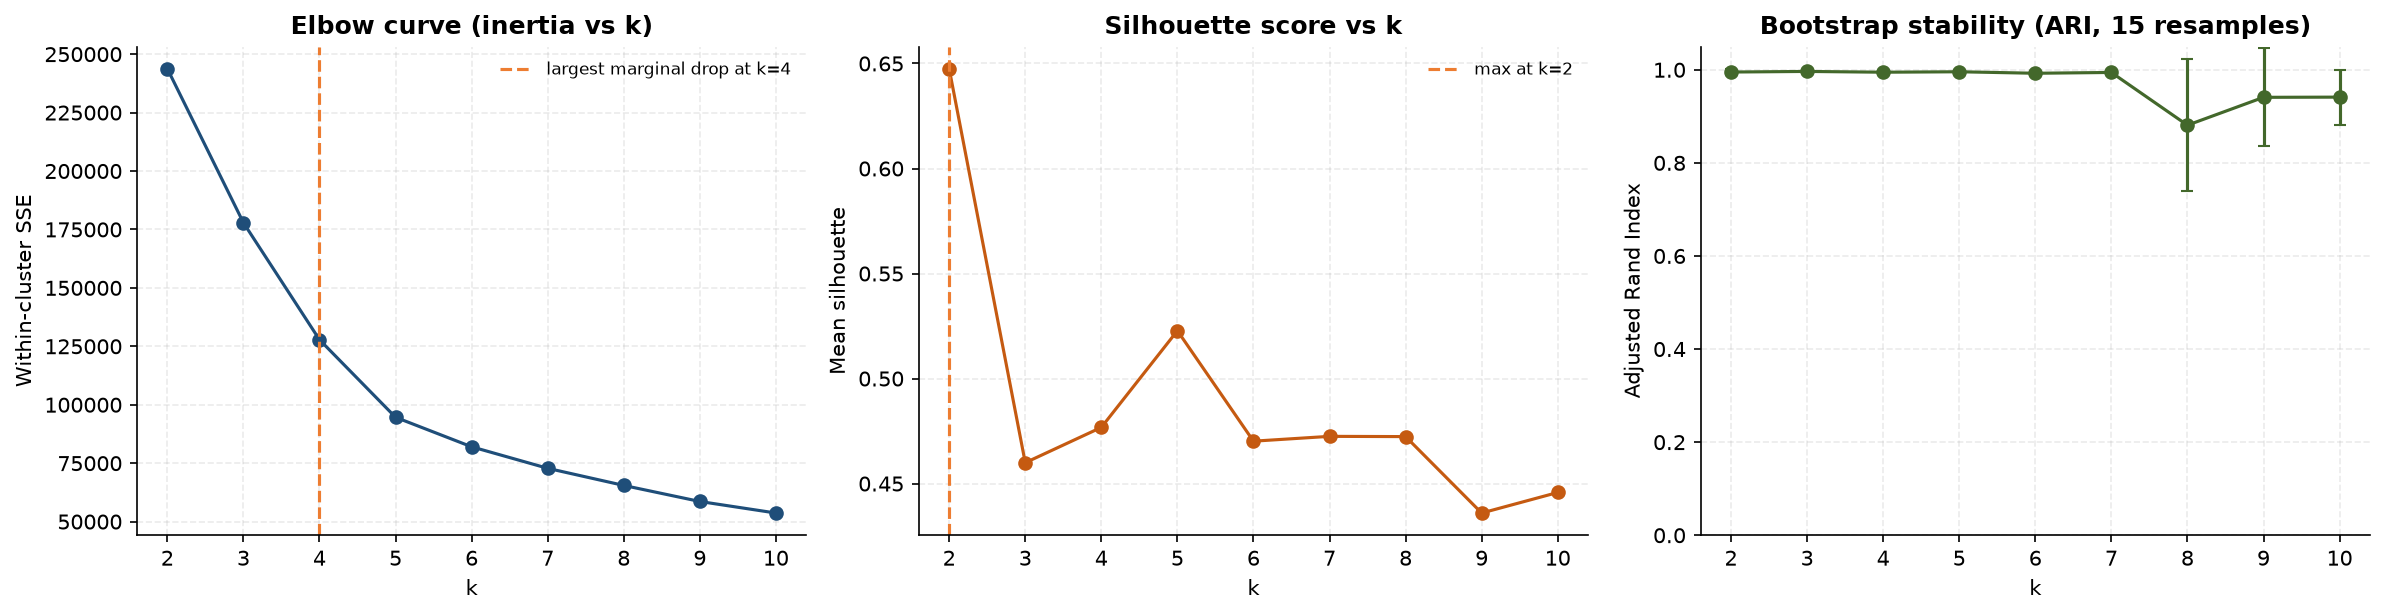

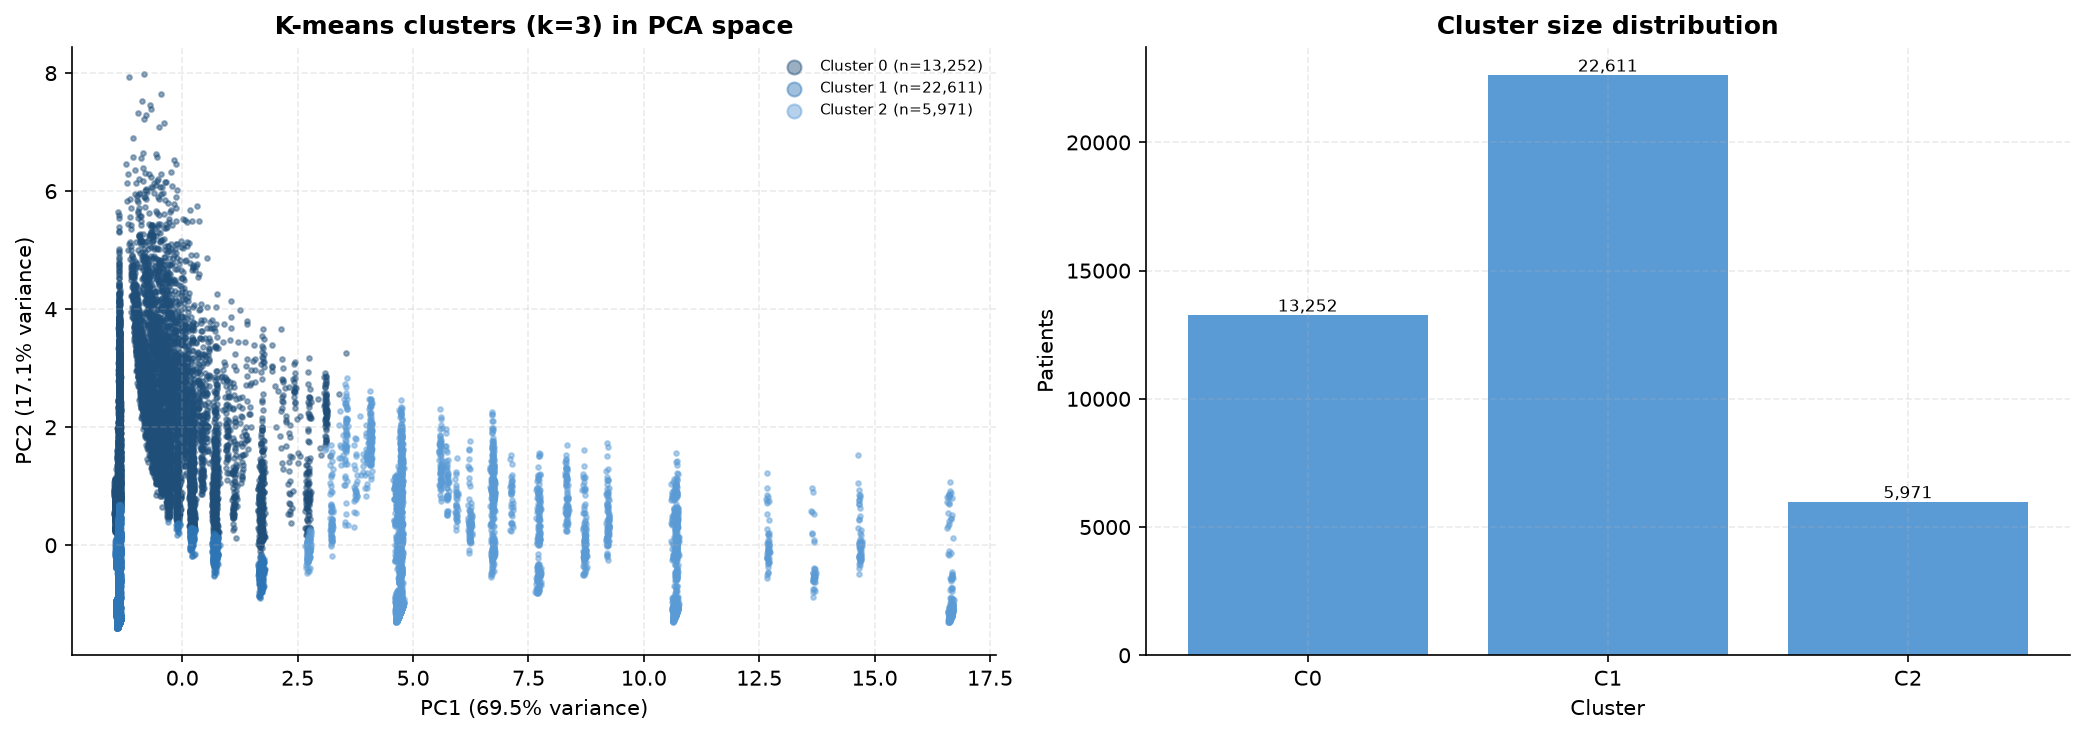

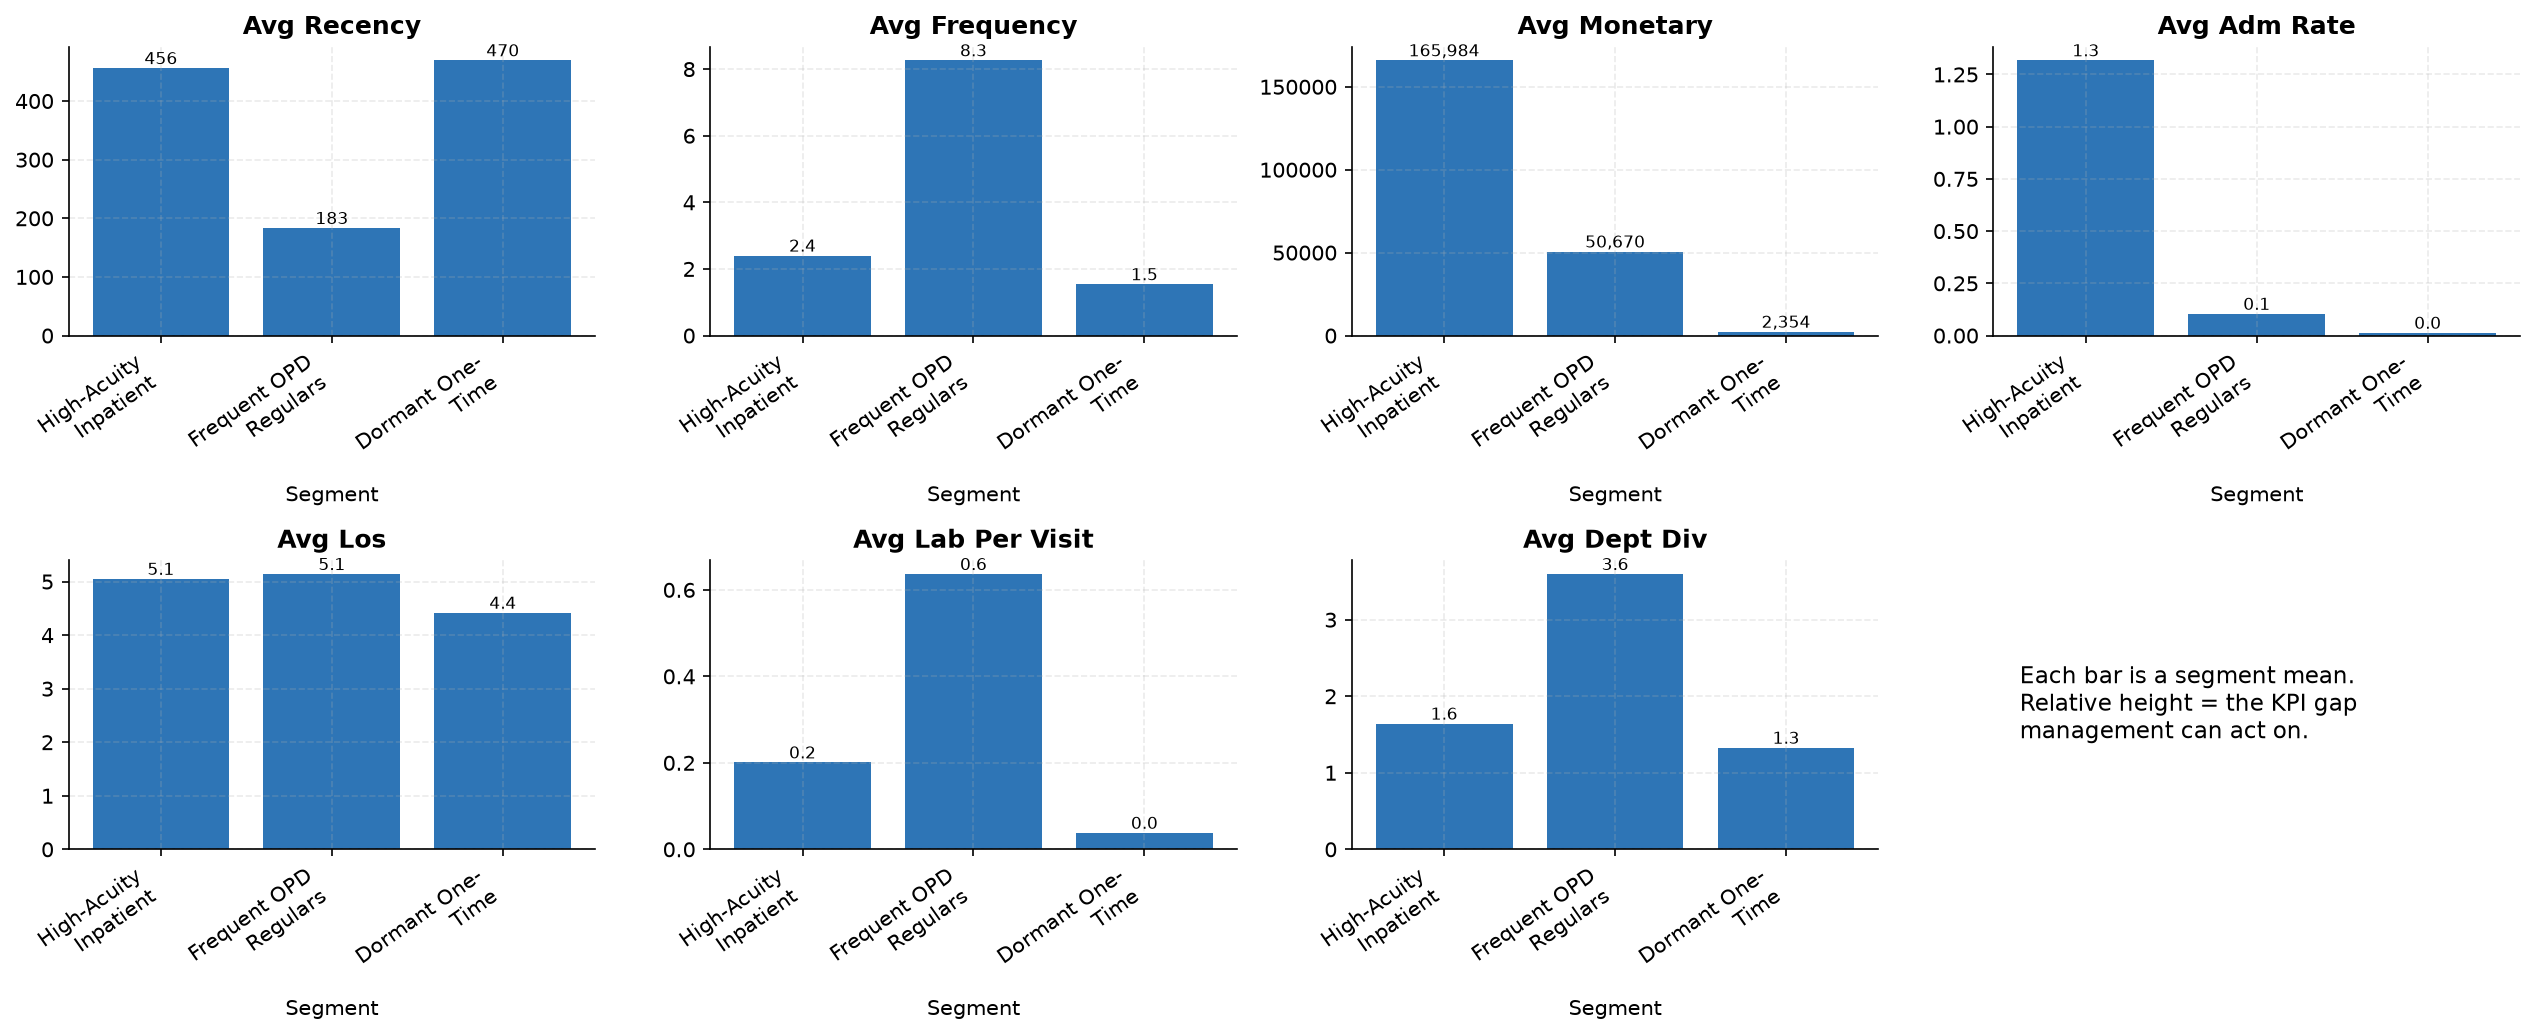

Chosen k: 3 | silhouette: 0.46 | CH: 42440.0 | DB: 0.95
ARI vs hidden latent archetypes (validation only): 0.156


In [17]:
from IPython.display import Image, display
for f in ["18_kmeans_model_selection","19_pca_clusters","20_cluster_profiles"]:
    display(Image(filename=str(C.FIG_DIR / f"{f}.png"), width=900))
km_metrics = json.loads((C.OUT_DIR / "kmeans_metrics.json").read_text())
print("Chosen k:", km_metrics["k"], "| silhouette:", round(km_metrics["silhouette"],3),
      "| CH:", round(km_metrics["calinski_harabasz"],0), "| DB:", round(km_metrics["davies_bouldin"],3))
print("ARI vs hidden latent archetypes (validation only):", round(km_metrics["ari_vs_latent_truth"],3))

## 9. Model comparison and selection

Selection is **not** made on silhouette alone. The composite operational utility score weights
KPI distinctiveness (0.30), segment-size balance (0.25), silhouette (0.25) and revenue separation (0.20),
and disqualifies any solution whose smallest segment falls below 5% of the patient base.

In [18]:
comp = pd.read_csv(C.OUT_DIR / "model_comparison.csv")
comp[["criterion","rfm","kmeans","winner"]]

,criterion,rfm,kmeans,winner
0,Number of segments produced,7 rule-based segments,3 empirical clusters,K-means
1,Smallest segment (% of base),2.8%,14.3%,Both pass
2,Silhouette (own feature space),0.284 (3-D score space),0.460 (8-D behavioural space),K-means
3,Bootstrap stability (ARI),0.046 period-over-period,0.996 resample / 0.158 period-over-period,K-means
4,Interpretability to a ward manager,High - a 3-number score per patient,"Medium - requires a profile table, but each cl...",RFM
5,Captures non-monetary behaviour,"No - only R, F and M enter the score","Yes - admissions, LOS, lab intensity, departme...",K-means
6,Segment size balance,32.6% largest vs 2.8% smallest,54.0% largest vs 14.3% smallest,K-means
7,Actionability / one intervention per segment,Weak - the residual tier mixes champions-in-wa...,Strong - each cluster maps to a distinct opera...,K-means
8,Threshold sensitivity,High - quantile cut-points move with the popul...,"Medium - centroids move, but assignment is rel...",K-means
9,Reproducibility,Fully deterministic,Deterministic given a seed; n_init=50 used,RFM


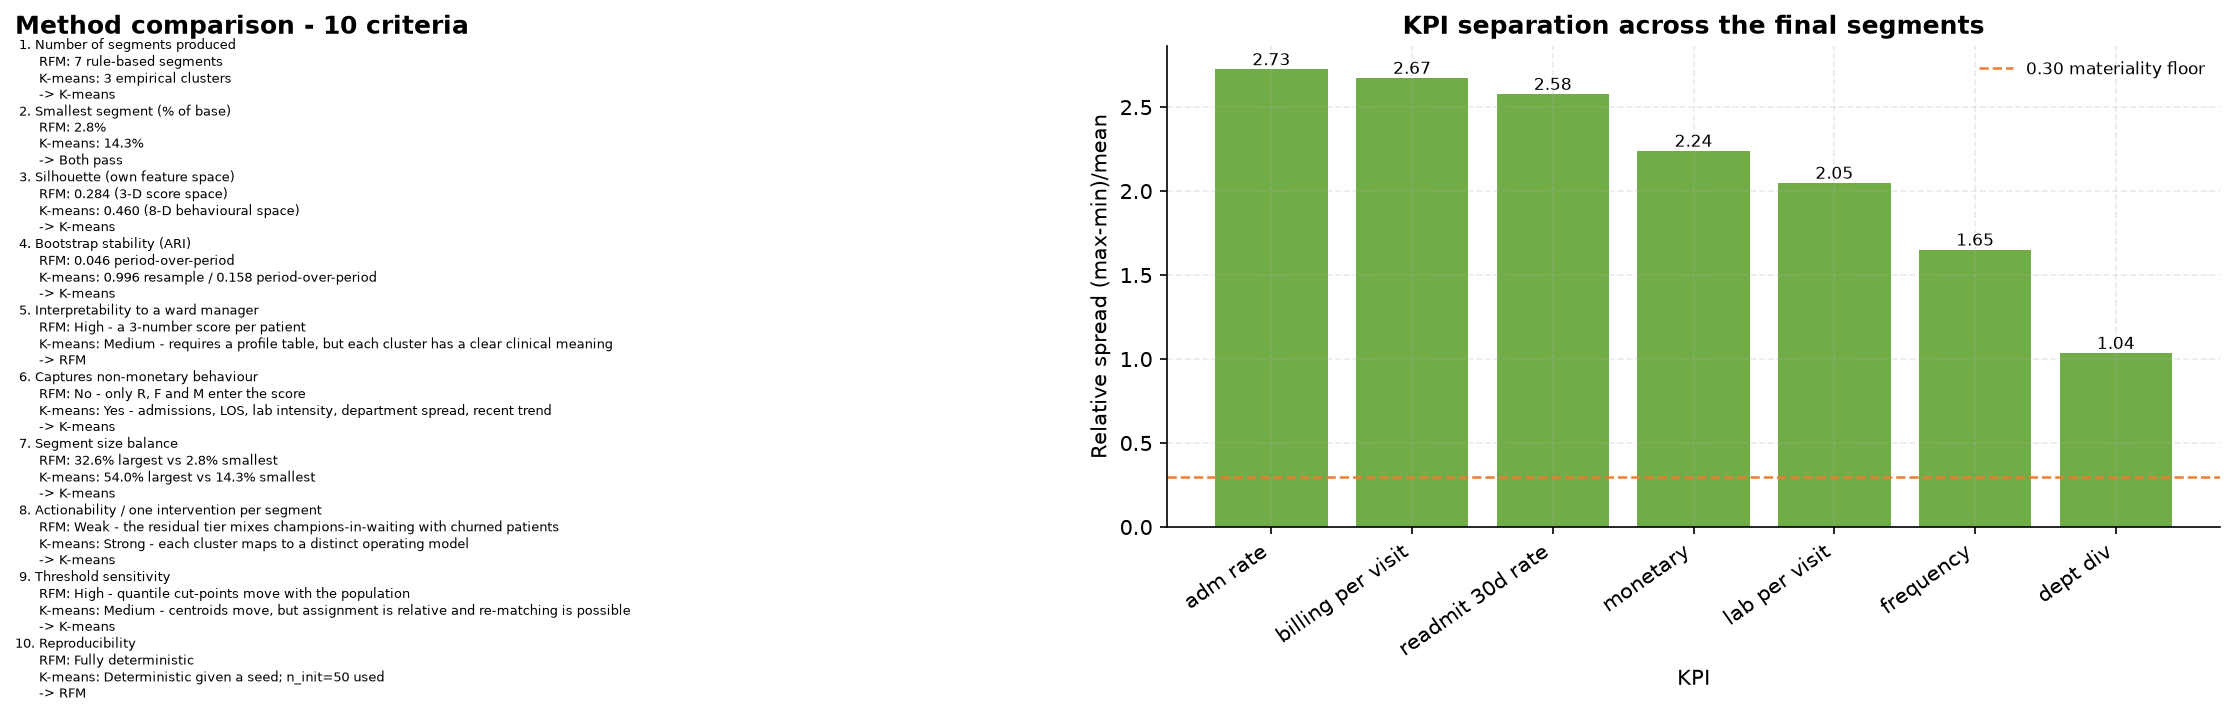

In [19]:
from IPython.display import Image, display
display(Image(filename=str(C.FIG_DIR / "25_model_comparison.png"), width=950))

## 10. Final segment profiles

Consolidated profile table for the final K-means segmentation. Every segment clears the 5% viability
floor. KPI differences are verified numerically in the next cell — none are manufactured.

In [20]:
prof = pd.read_csv(C.OUT_DIR / "final_segment_profiles.csv")
cols = ["segment_name","n_patients","share_pct","revenue","revenue_share_pct","avg_recency",
        "avg_frequency","avg_monetary","avg_billing_per_visit","avg_los","avg_adm_rate",
        "avg_lab_per_visit","avg_dept_div","readmit_30d_rate","bed_days_per_100","avg_age","pct_female"]
prof[cols].round(2)

,segment_name,n_patients,share_pct,revenue,revenue_share_pct,avg_recency,avg_frequency,avg_monetary,avg_billing_per_visit,avg_los,avg_adm_rate,avg_lab_per_visit,avg_dept_div,readmit_30d_rate,bed_days_per_100,avg_age,pct_female
0,High-Acuity Inpatient,5971,14.27,9.910923e+08,57.76,456.18,2.40,165984.32,67043.37,5.05,1.32,0.20,1.64,0.27,1633.68,48.11,0.52
1,Frequent OPD Regulars,13252,31.68,6.714746e+08,39.13,183.48,8.27,50669.68,5591.99,5.14,0.10,0.64,3.60,0.04,482.18,45.51,0.52
2,Dormant One-Time,22611,54.05,5.322579e+07,3.10,469.55,1.54,2353.98,1208.07,4.42,0.01,0.04,1.33,0.00,16.45,37.56,0.52


In [21]:
diffs = pd.read_csv(C.OUT_DIR / "segment_kpi_differences.csv")
print(f"{int((diffs.relative_spread>=0.30).sum())} of {len(diffs)} KPIs exceed the 0.30 materiality floor:")
diffs[["kpi","min_segment_value","max_segment_value","max_over_min_x","relative_spread"]].round(3)

8 of 9 KPIs exceed the 0.30 materiality floor:


,kpi,min_segment_value,max_segment_value,max_over_min_x,relative_spread
0,avg_adm_rate,0.014,1.318,97.52,2.726
1,avg_billing_per_visit,1208.072,67043.373,55.50,2.675
2,readmit_30d_rate,0.000,0.272,inf,2.579
3,avg_monetary,2353.978,165984.315,70.51,2.241
4,avg_lab_per_visit,0.038,0.637,16.67,2.050
5,avg_frequency,1.542,8.265,5.36,1.652
6,avg_dept_div,1.328,3.597,2.71,1.037
7,avg_recency,183.481,469.551,2.56,0.774
8,avg_los,4.419,5.141,1.16,0.148


## 11. Segment stability and migration

The window is split into two independent 18-month periods, features are recomputed separately with
period-specific reference dates, K-means is re-fit independently, and period-2 clusters are matched to
period-1 clusters by **profile using the Hungarian algorithm** — never by assuming cluster ids persist.

Patients P1 28,728 | P2 29,642 | in both 16,536
Cluster matching P2 -> P1: {'1': 0, '0': 2, '2': 1}
ARI K-means: 0.158 | ARI RFM: 0.046
Off-diagonal migration: 50.0%

Retention by segment:
  High-Acuity Inpatient       20.3%
  Frequent OPD Regulars       92.1%
  Dormant One-Time             8.9%


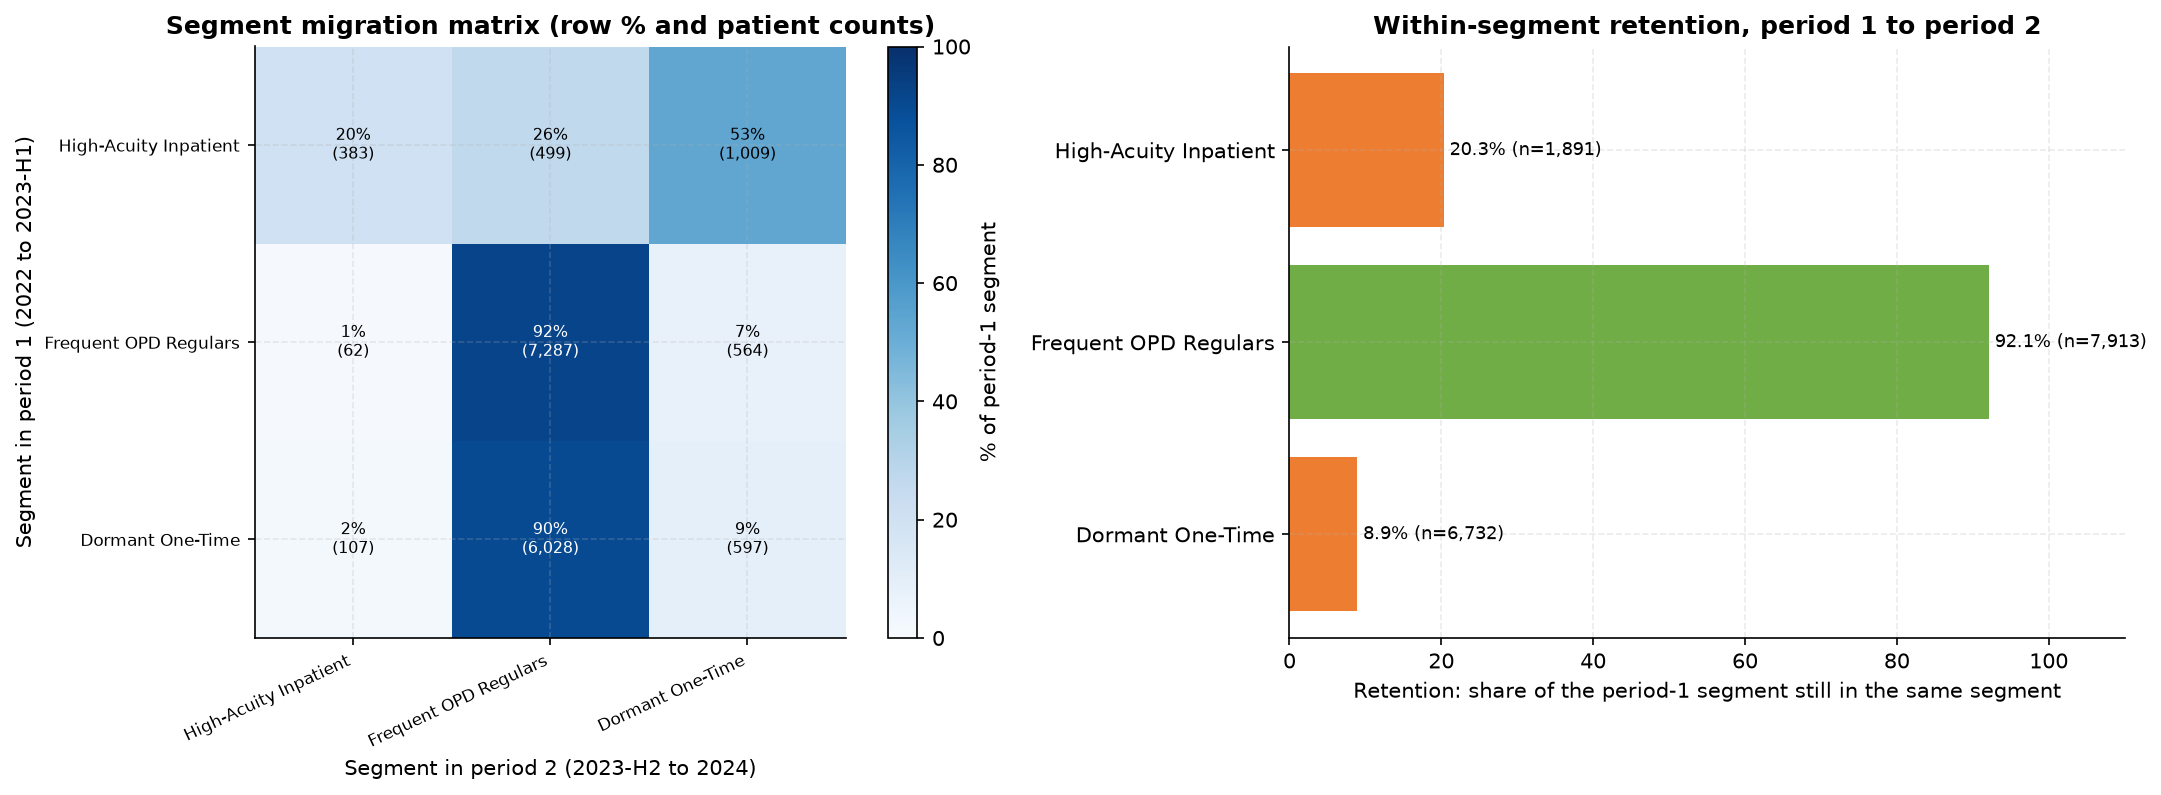

In [22]:
from IPython.display import Image, display
stab = json.loads((C.OUT_DIR / "stability_summary.json").read_text())
print(f"Patients P1 {stab['patients_p1']:,} | P2 {stab['patients_p2']:,} | in both {stab['patients_both']:,}")
print(f"Cluster matching P2 -> P1: {stab['cluster_mapping_p2_to_p1']}")
print(f"ARI K-means: {stab['ari_kmeans']:.3f} | ARI RFM: {stab['ari_rfm']:.3f}")
print(f"Off-diagonal migration: {stab['off_diagonal_pct']:.1f}%")
print("\nRetention by segment:")
for k,v in stab["retention_pct"].items(): print(f"  {k:26s} {v:5.1f}%")
display(Image(filename=str(C.FIG_DIR / "22_segment_migration.png"), width=950))

In [23]:
pd.read_csv(C.OUT_DIR / "migration_matrix_kmeans.csv", index_col=0)

,High-Acuity Inpatient,Frequent OPD Regulars,Dormant One-Time
segment_name,,,
High-Acuity Inpatient,383,499,1009
Frequent OPD Regulars,62,7287,564
Dormant One-Time,107,6028,597


In [24]:
pd.read_csv(C.OUT_DIR / "segment_size_drift.csv").round(2)

,P1_patients,P2_patients,P1_avg_monetary,P2_avg_monetary,P1_avg_frequency,P2_avg_frequency,P1_avg_recency,P2_avg_recency,patient_growth_pct
0,6732,2170,4119.0,134300.0,1.81,2.89,183.0,178.0,-67.8
1,7913,13814,34808.0,20046.0,5.49,4.30,95.0,157.0,74.6
2,1891,552,165463.0,240283.0,2.18,1.91,178.0,225.0,-70.8


## 12. Recommendations and cost-benefit analysis

Four interventions, one per segment plus one network-wide. Each is linked to a measured finding, and
the financial model separates **observed** inputs from **assumed** parameters. Sensitivity is reported
for the governing assumption of each case.

In [25]:
rec = pd.read_csv(C.OUT_DIR / "recommendations_cost_benefit.csv")
rec[["segment","segment_n","problem","intervention","kpi","timeline"]].T

,0,1,2,3
segment,High-Acuity Inpatient,Dormant One-Time,Frequent OPD Regulars,Network-wide
segment_n,5971,22611,13252,13565
problem,This segment is 14.3% of patients but 57.8% of...,"22,611 patients (54.0% of the base) average 1....",This segment orders 0.64 laboratory tests per ...,"13,565 patients account for 165,165 bed-days a..."
intervention,Post-discharge bundle for every admitted patie...,Population reactivation and preventive screeni...,Diagnostics stewardship and chronic-care packa...,Segment-aware discharge and ALOS management: r...
kpi,30-day readmission rate for this segment; 7-da...,"Camp attendance per 1,000 invited; 90-day reac...",Tests per visit; share of orders matching an a...,ALOS by department; % discharges with a comple...
timeline,Design month 1; pilot at two sites months 2-3;...,Wave 1 month 2; wave 2 month 4; steady state b...,Order sets months 1-2; LIS rules month 3; clin...,Pilot at two sites months 1-3; network rollout...


In [26]:
rec[["segment","cost_total","benefit_value","net_benefit","roi_pct",
     "benefit_cost_ratio","payback_months","benefit_units"]].round(2)

,segment,cost_total,benefit_value,net_benefit,roi_pct,benefit_cost_ratio,payback_months,benefit_units
0,High-Acuity Inpatient,1762000.0,5789892.0,4027892.0,228.6,3.29,3.7,"243 avoidable readmissions prevented; 5,971 gu..."
1,Dormant One-Time,526215.0,647544.0,121329.0,23.1,1.23,9.8,"621 reactivated patients, 1,180 visits, 869 sc..."
2,Frequent OPD Regulars,1080000.0,4114782.0,3034782.0,281.0,3.81,3.1,"421 avoidable test episodes removed, 1,700 pac..."
3,Network-wide,2900000.0,22836632.0,19936632.0,687.5,7.87,1.5,"9,910 bed-days released (3,964 monetised at a ..."


In [27]:
sens = pd.read_csv(C.OUT_DIR / "recommendation_sensitivity.csv")
sens.pivot_table(index="segment", columns="scenario", values="roi_pct").round(0)

scenario,Base,Optimistic,Pessimistic
segment,,,
Dormant One-Time,23.0,85.0,-38.0
Frequent OPD Regulars,281.0,472.0,90.0
High-Acuity Inpatient,229.0,393.0,64.0
Network-wide,688.0,1081.0,294.0


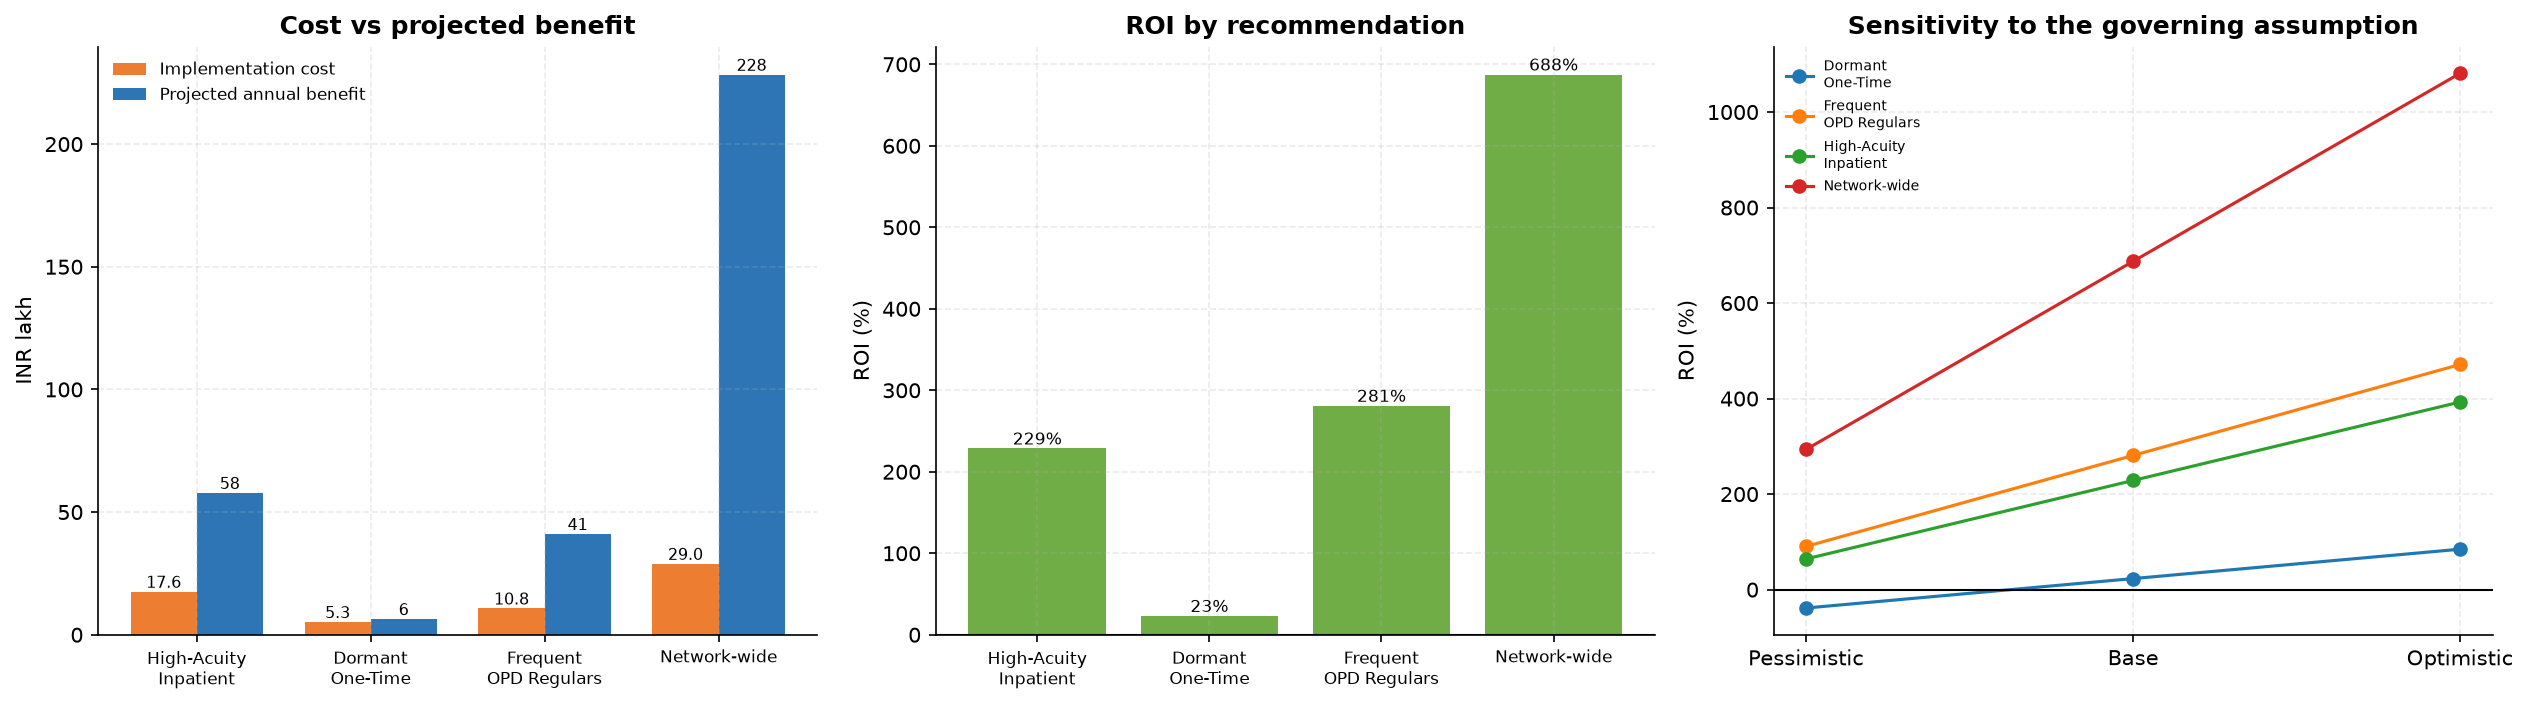

Portfolio cost INR 6,268,215 | benefit INR 33,388,850 | ROI 433%


In [28]:
from IPython.display import Image, display
display(Image(filename=str(C.FIG_DIR / "24_cost_benefit.png"), width=980))
print(f"Portfolio cost INR {rec.cost_total.sum():,.0f} | benefit INR {rec.benefit_value.sum():,.0f} "
      f"| ROI {100*(rec.benefit_value.sum()-rec.cost_total.sum())/rec.cost_total.sum():.0f}%")

## 12b. Limitations

1. **All data is synthetic.** Absolute counts, revenue and ROI must not be quoted as hospital facts.
2. Gross billing is observed; **cost is not**. Contribution-margin rates (OPD 38%, IPD 30%, lab 42%)
   are declared assumptions, and every ROI is therefore a margin-weighted estimate.
3. K-means assumes roughly spherical, similarly-sized clusters and is sensitive to initialisation and
   outliers. Mitigations used: `n_init=50`, log1p transforms, RobustScaler, bootstrap ARI reporting.
4. Twelve-month-forward benefits are modelled from cross-sectional unit economics; no holdout
   experiment was run, so uplift figures are projections, not measured effects.
5. Segment membership is a snapshot. The migration analysis shows 30-day-style churn is material, so
   the model must be re-scored monthly, not annually.
6. `followup_compliance` is measurable for only the subset of visits with a recorded plan
   (~41% of the base) and is reported with that caveat.
7. Bed capacity and occupancy are modelled network parameters, not measured ward-level census data.

---
### Reproducibility
```bash
pip install -r requirements.txt
python src/generate_synthetic_data.py   # rebuild the raw extract (seed 20241111)
python src/cleaning.py                  # clean + validate
python src/features.py                  # patient-level features
python src/eda.py                       # EDA and statistical analysis
python src/segmentation.py              # RFM + K-means + model selection
python src/stability.py                 # period split, migration, ARI
python src/recommendations.py           # cost-benefit model
python src/model_comparison.py          # comparison table + KPI verification
python src/build_deliverables.py        # Excel workbook, Word report, PowerPoint
```